<a href="https://colab.research.google.com/github/DinRazar/data-data/blob/main/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №3. Сравнительный анализ базовых и ансамблевых методов машинного обучения в задачах классификации текстов**

---

## **Введение**

Отзывы об организациях содержат два источника информации: текст с описанием опыта посетителя и оценку от 1 до 5 звёзд. Их сопоставление позволяет выявить случаи, требующие подробного анализа: неоднозначные тексты, расхождения между содержанием и оценкой, а также ошибки моделей.

Методы классификации текстов применяются для определения тональности и прогнозирования оценки по содержанию отзыва. Результаты объединяются со сведениями об организациях и их координатами, чтобы сравнить отзывы выбранных территорий и отобразить выявленные расхождения на карте.

**🎯 Цель работы:** освоить построение и оценку моделей классификации русскоязычных текстов и применить их к анализу отзывов об организациях с учётом пространственного расположения объектов.

**Задачи работы:**

1. Подготовить текстовые данные и сравнить мешок слов, TF-IDF, Word2Vec, Doc2Vec и современные нейросетевые эмбеддинги.
2. Обучить и сравнить классификаторы тональности, подобрать параметры и оценить качество на тестовой выборке.
3. Построить модель прогнозирования оценки по тексту отзыва с разделением данных по организациям.
4. Сформулировать правило отбора отзывов, в которых текст может расходиться с оценкой, и проверить его по результатам чтения.
5. Собрать отзывы выбранных территорий, подготовить сводку по организациям и карты тональности, оценок и расхождений.
6. Сравнить результаты для двух территорий и сформулировать выводы с учётом качества моделей и ограничений выборки.

**Данные:**

- [RuSentiTweet](https://github.com/sismetanin/rusentitweet) — русскоязычные сообщения с разметкой тональности;
- [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) — отзывы об организациях с оценками от 1 до 5;
- свежие отзывы выбранной территории, которые вы соберёте [сборщиком отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews).

**Структура работы:**

| Часть | Вопрос исследования | Результат |
|---|---|---|
| 1. Тональность текста | Какое представление текста и какой классификатор позволяют точнее определить тональность? | Модель тональности и сравнение методов |
| 2. Оценка по тексту | Насколько точно можно предсказать оценку и как отобрать расхождения между текстом и звёздами? | Модель оценки, правило отбора и опорная частота расхождений |
| 3. Анализ территорий | Какие расхождения встречаются в собранных отзывах и различаются ли территории? | Проверенные примеры, сводка по организациям, карты и сравнение двух территорий |

> 📝 **Как выполнять работу.** Выполняйте ячейки сверху вниз. В ячейках `# ВАШ КОД` напишите своё решение; в некоторых из них уже есть заготовка — замените многоточия. Чтобы ответить на вопрос, дважды щёлкните по ячейке «Ответ», впишите текст и нажмите `Shift+Enter`.

---

## **Часть 0. Настройка окружения**

Откройте блокнот в Colab и включите видеокарту: **Среда выполнения → Сменить среду выполнения → GPU**. Затем установите библиотеки и выполните импорты.

In [ ]:
# Устанавливаем библиотеки для векторизации, классификации и карт.
%pip install -q scikit-learn==1.7.2 gensim==4.4.0 lightgbm==4.7.0 sentence-transformers==5.2.0 transformers==4.57.6 pyarrow geopandas folium osmnx==2.1.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 66.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.7/493.7 kB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 66.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.4/104.4 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 77.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.

In [ ]:
import os  # Задаём число вычислительных потоков.
from pathlib import Path  # Работаем с путями к файлам.
THREADS = min(6, os.cpu_count() or 1)  # Используем не больше доступного числа процессоров.
os.environ['OMP_NUM_THREADS'] = str(THREADS)  # Ограничиваем потоки вычислительных библиотек.
os.environ['MKL_NUM_THREADS'] = str(THREADS)  # Согласуем потоки линейной алгебры.

import numpy as np  # Работаем с массивами.
import pandas as pd  # Работаем с таблицами.
import matplotlib.pyplot as plt  # Строим графики.
import seaborn as sns  # Показываем распределения и матрицы ошибок.
import torch  # Проверяем доступность видеокарты.
from IPython.display import display  # Выводим таблицы и карты.

SEED = 42  # Фиксируем случайность разделений и обучения.
np.random.seed(SEED)  # Повторяем случайный выбор примеров.
torch.set_num_threads(THREADS)  # Ограничиваем потоки PyTorch.
device = 'cuda' if torch.cuda.is_available() else 'cpu'  # Выбираем устройство для эмбеддингов.
pd.set_option('display.max_colwidth', None)  # Показываем тексты целиком.
plt.rcParams['figure.figsize'] = (9, 4)  # Задаём размер графиков.
print('Устройство:', device)  # Проверяем, подключена ли видеокарта.

Устройство: cuda


> **18+.** Пользовательские тексты могут содержать ненормативную лексику. Для просмотра таблиц с текстами используйте функцию `show(...)`: она заменяет такие слова на `[скрыто]` только при показе, а данные для обучения не меняет.

In [ ]:
# Готовая функция для вывода текстов
import base64, gzip, re  # Подключаем средства чтения встроенных правил.
display_pattern = re.compile(gzip.decompress(base64.b64decode('H4sIAAAAAAACCl1QMQ7CMBB7CxvwBBYeknYpEgIxAmK5oVAhNhA/CSKBQmn5gu9HOEknFut8d7F9yYrhdDCcTmDR6p74wQ2NsGy0wgOetBV80elBy0g5rf4aJHu8iWWiqbRpueR67Lq+iD5pFN97OqRSr8Gs6bsuCiU6ynbjrAjIsHrUyuAFr1e9oNZzzoQGNXyOJ5+ZMMlx6+8SWD0QQoZWK8bXU3DpAtQEvQiVuOIjoB1JyGcoTkUXCXeobeO3fIXfRGE4WMG9L7vg9OHYGXa6HG+Zb2crWS+WGymWm9kiHfED+6yyw3MBAAA=')).decode('utf-8'), re.IGNORECASE)  # Подготавливаем фильтр.
def show(frame):  # Маскируем текст только в отображаемой копии.
    shown = frame.to_frame() if isinstance(frame, pd.Series) else frame.copy()  # Сохраняем исходные значения.
    for column in shown.select_dtypes(include=['object','string']):  # Обрабатываем текстовые поля.
        shown[column] = shown[column].astype(str).str.replace(display_pattern,'[скрыто]',regex=True)  # Скрываем совпадения.
    display(shown)  # Показываем подготовленную таблицу.

---

## **Часть 1. Тональность текста**

**Задача:** по тексту сообщения определить его тональность — отрицательную, нейтральную или положительную.

**Датасет:** [RuSentiTweet](https://github.com/sismetanin/rusentitweet) содержит русскоязычные сообщения социальной сети, размеченные по тональности. В корпусе есть обучающая и тестовая части. Тестовую часть оставим для итоговой проверки, а из обучающей выделим валидацию для выбора моделей и параметров.

Обученная модель понадобится в частях 2 и 3: она станет первым «читателем» отзывов.

### **1.1. Загрузка и первичный осмотр данных**

> 📚 **Подсказка:** Загрузка корпуса и чтение CSV показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=hJVEXL-bcVRg).

In [ ]:
if not Path('rusentitweet').exists():  # При повторном запуске используем уже скачанную папку.
    !git clone -q --depth 1 https://github.com/sismetanin/rusentitweet.git rusentitweet
train_source = pd.read_csv('rusentitweet/rusentitweet_train.csv')  # Читаем обучающую часть.
test_source = pd.read_csv('rusentitweet/rusentitweet_test.csv')  # Читаем тестовую часть.
show(train_source.head())  # Смотрим столбцы и примеры.

,text,label,id
0,Помойму я вкрашилась в Чимина🤧 https://t.co/t2uZTS7NH2,positive,1282311169534038016
1,@namaskaramsaroo Мотоцикль,neutral,1272864221202530309
2,Михаил Мишустин: меры по борьбе с коронавирусом в России были своевременные и правильные https://t.co/bYMCUoZDMk,neutral,1296860899739947008
3,@bbsbro_ доброй ноченьки 💕,speech,1288168112425246721
4,ну что пойду чекну фоточки,neutral,1287678712612364288


**1. Выведите размеры обучающей и тестовой частей, число пропусков и количество примеров каждой исходной метки.**

In [ ]:
print('train:', train_source.shape)
print('test:', test_source.shape)
print('\nПропуски train:')
print(train_source.isna().sum())
print('\nПропуски test:')
print(test_source.isna().sum())
print('\nМетки train:')
print(train_source.label.value_counts())
print('\nМетки test:')
print(test_source.label.value_counts())

train: (10713, 3)
test: (2679, 3)

Пропуски train:
text     0
label    0
id       0
dtype: int64

Пропуски test:
text     0
label    0
id       0
dtype: int64

Метки train:
label
neutral     4273
negative    2638
positive    1931
skip        1474
speech       397
Name: count, dtype: int64

Метки test:
label
neutral     1068
negative     660
positive     483
skip         369
speech        99
Name: count, dtype: int64


**2. Покажите по три случайных текста классов `negative`, `neutral` и `positive`.**

In [ ]:
for lab in ['negative', 'neutral', 'positive']:
    print(f'=== {lab} ===')
    show(train_source.loc[train_source.label == lab].sample(3, random_state=SEED)[['text', 'label']])

=== negative ===


,text,label
6295,Максимально допустимая продолжительность видео — 2 минуты 20 секунд.\r\n\r\nО нет.....,negative
4398,опять ошибки да ок понятно тупица м,negative
9648,@chern_ov Мне самой кажется эстетичным носы с горбинкой\r\nНо свой из за неё я буквально ненавижу\r\n¯\_༼ •́ ͜ʖ •̀ ༽_/¯,negative


=== neutral ===


,text,label
3630,"Правильно пишется ""Конституции""",neutral
2963,@shkolar92 Так я ж не парней с видео имел ввиду. Ты наверно не совсем понял этот твит),neutral
784,@ybudyan @SkunkAngry @Alex_zhzhet Квартира в наследство досталась.,neutral


=== positive ===


,text,label
5918,хорошо мой павелитель 🙏🏻 https://t.co/pNYA8ucoYw,positive
9143,@JoomOfficialRu вроде смешно https://t.co/Oo3uOblGSb,positive
10349,Ничего необычного) 😂 https://t.co/mYrxsYTtmX,positive


**Как читать разметку.** `positive` и `negative` — выраженная положительная или отрицательная оценка; `neutral` — содержательное сообщение без выраженной оценки. `speech` обозначает речевые акты (приветствие, поздравление), `skip` — сообщения, тональность которых определить трудно. В работе используем первые три класса. [Описание корпуса](https://github.com/sismetanin/rusentitweet).

**Вопрос:** Сколько примеров каждого из трёх используемых классов в обучающей части? Почему классы `speech` и `skip` не объединяем с `neutral`?

**Ответ:** speech — это речевые акты (приветствия, поздравления) без оценки, а skip — неоднозначные; объединение с neutral размыло бы класс «содержательное сообщение без оценки» и ухудшило бы обучение.

---

### **1.2. Очистка и разделение данных**

Один и тот же текст не должен встречаться в нескольких частях: иначе итоговая проверка частично измеряла бы запоминание. Для поиска повторов создаём ключ — текст без различий регистра и пробелов. Повторы с разными метками удаляем как противоречивые. Исходный текст сохраняем для признаков и чтения.

In [ ]:
from sklearn.model_selection import train_test_split  # Выделяем валидацию.

def text_key(column):  # Ключ для поиска одинаковых текстов.
    return column.fillna('').astype(str).str.normalize('NFKC').str.replace(r'\s+', ' ', regex=True).str.strip().str.casefold()  # Убираем различия регистра и пробелов.

labels = ['negative', 'neutral', 'positive']  # Три целевых класса.
prepared = {}  # Подготовленные исходные части.
for name, frame in [('train', train_source), ('test', test_source)]:  # Обрабатываем обе части одинаково.
    frame = frame.copy()  # Не меняем исходную таблицу.
    frame['text_key'] = text_key(frame.text)  # Ключ каждого текста.
    conflict = frame.groupby('text_key').label.transform('nunique').gt(1)  # Одинаковые тексты с разными метками.
    keep = frame.label.isin(labels) & frame.text_key.ne('') & ~conflict  # Пригодные записи.
    prepared[name] = frame.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Удаляем повторы.

test = prepared['test']  # Итоговая проверка.
development = prepared['train'].loc[~prepared['train'].text_key.isin(test.text_key)]  # Убираем из обучения тексты теста.
train, valid = train_test_split(development, test_size=0.2, stratify=development.label, random_state=SEED)  # Сохраняем доли классов.
train, valid = train.reset_index(drop=True), valid.reset_index(drop=True)  # Последовательные индексы.

**Выведите численность классов в `train`, `valid` и `test` и проверьте, что ни одна пара частей не имеет общих текстов (по столбцу `text_key`).**

<details>
<summary><b>Пример кода</b></summary>

```python
show(pd.DataFrame({'train': train.label.value_counts(), 'valid': valid.label.value_counts()}))
print('train / valid:', len(set(train.text_key) & set(valid.text_key)))
```

</details>

In [ ]:
show(pd.DataFrame({
    'train': train.label.value_counts(),
    'valid': valid.label.value_counts(),
    'test':  test.label.value_counts()
}))
print('train / valid:', len(set(train.text_key) & set(valid.text_key)))
print('train / test :', len(set(train.text_key) & set(test.text_key)))
print('valid / test :', len(set(valid.text_key) & set(test.text_key)))

,train,valid,test
label,,,
neutral,3418,855,1068
negative,2110,528,660
positive,1545,386,483


train / valid: 0
train / test : 0
valid / test : 0


> 📚 **Подсказка:** train нужен для обучения, valid — для выбора модели и параметров, test — для итоговой оценки после выбора. [**Разделение данных и кросс-валидация**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=hc87mctOPspb).

**Вопрос:** Зачем нужна валидация, если в корпусе уже есть тестовая часть?

**Ответ:** тест — для финальной оценки после выбора модели; валидация — для выбора модели/параметров, чтобы не «подглядывать» в тест и не переобучиться под него.

---

### **1.3. Разведочный анализ и гипотезы**

> 📚 **Подсказка:** [**Занятие 2: распределение классов**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan#scrollTo=15c684d7); [**Macro-F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=0c5d5827).

**1. Постройте распределение классов в обучающей части.**

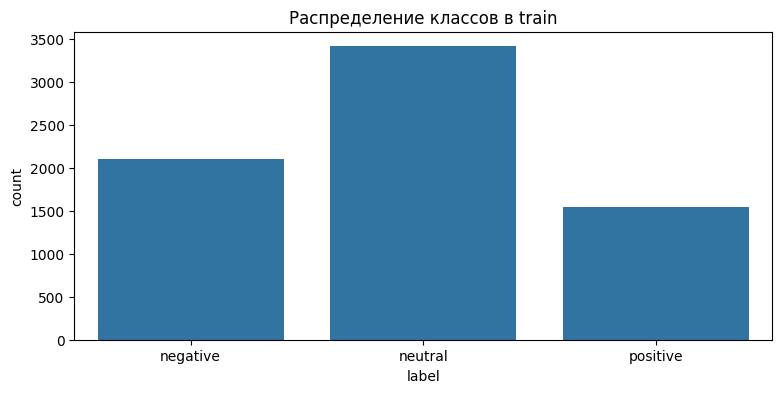

In [ ]:
sns.countplot(data=train, x='label', order=labels)
plt.title('Распределение классов в train')
plt.show()

**2. Сравните длину текстов (в символах) по классам с помощью `boxplot`.**

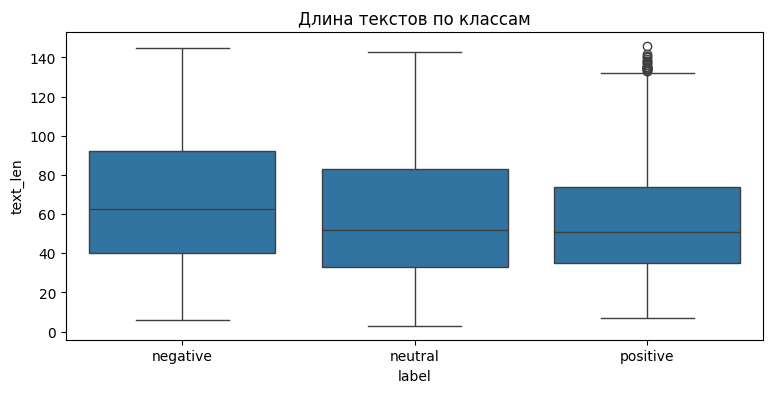

In [ ]:
train = train.assign(text_len=train.text.str.len())
sns.boxplot(data=train, x='label', y='text_len', order=labels)
plt.title('Длина текстов по классам')
plt.show()

Чтобы гипотезы о признаках были осмысленными, сравните способы представления текста, которые будут использованы дальше:

| Представление | Что описывает вектор текста | Обучается на наших данных? |
|---|---|---|
| BoW (мешок слов) | Частоты слов и пар соседних слов | Словарь — да |
| TF-IDF | Те же частоты, взвешенные по редкости слова в обучающих текстах | Словарь и веса — да |
| Средний Word2Vec | Среднее векторов слов текста | Да |
| Doc2Vec | Вектор документа, выведенный обученной моделью | Да |
| E5, Giga | Вектор текста из готовой нейросети, учитывающей контекст слов | Нет, веса готовые |

Главная метрика сравнения — **macro-F1**: среднее F1 по трём классам, где каждый класс имеет одинаковый вес. Дополнительно смотрим accuracy и время обучения.

Сформулируйте **две гипотезы**: одну о представлении текста, другую — о классификаторе или учёте дисбаланса классов. Для каждой укажите наблюдение или теоретическое соображение, ожидаемое изменение macro-F1 и способ проверки.

| № | Наблюдение или соображение | Гипотеза | Как проверить |
|---|---|---|---|
| 1 | ... | ... | ... |
| 2 | ... | ... | ... |

<details>
<summary><b>Подсказка к формулировке гипотез</b></summary>

Мешок слов хранит частоты отдельных слов и, при `ngram_range=(1, 2)`, соседних пар. Пара «не понравилось» может войти в словарь, но порядок всего предложения и близость синонимов такое представление не описывает. Какое представление может учесть больше контекста и для какого классификатора это окажется полезным? Посмотрите на распределение классов: как самый частый класс повлияет на accuracy постоянного прогноза?

Пример гипотезы: «На эмбеддингах E5 SVM получит macro-F1 выше, чем на TF-IDF, потому что вектор E5 учитывает контекст; проверим по таблице сравнения».

</details>

**Гипотезы:** Гипотеза 1: эмбеддинги E5/Giga дадут более высокий macro-F1, чем BoW/TF-IDF, потому что учитывают контекст. Проверка — тепловая карта comparison.

Гипотеза 2: class_weight='balanced' у SVM/LogReg улучшит macro-F1 по редким классам по сравнению с моделями без балансировки. Проверка — сравнение с/без class_weight.

**Вопрос:** Почему при таком распределении классов нельзя выбирать модель только по accuracy?

**Ответ:** классы несбалансированы; постоянный прогноз самого частого класса даст высокую accuracy, но macro-F1 будет низким. Нужна macro-F1.

---

### **1.4. Мешок слов и TF-IDF**

> 📚 **Подсказка:** Построение мешка слов и TF-IDF показано в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=9jTeKixplgYk). Сравните методы `fit_transform` и `transform`.

Мешок слов превращает текст в частоты слов и соседних пар: каждому элементу словаря соответствует столбец матрицы. TF-IDF изменит веса этих частот, чтобы отличать распространённые слова от более редких.

Словарь и веса строим **только по обучающей части**. Валидацию и тест преобразуем теми же объектами методом `transform`: иначе одинаковые столбцы могут обозначать разные слова.

**1. Создайте `bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64)` и получите `X_bow_train`, `X_bow_valid`, `X_bow_test`.**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer  # Словарные признаки.
bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64)
X_bow_train = bow.fit_transform(train.text)
X_bow_valid = bow.transform(valid.text)
X_bow_test  = bow.transform(test.text)
print(X_bow_train.shape, X_bow_valid.shape, X_bow_test.shape)

(7073, 7136) (1769, 7136) (2211, 7136)


**2. Создайте `tfidf = TfidfTransformer()` и получите `X_tfidf_train`, `X_tfidf_valid`, `X_tfidf_test` из матриц мешка слов.**

In [ ]:
tfidf = TfidfTransformer()
X_tfidf_train = tfidf.fit_transform(X_bow_train)
X_tfidf_valid = tfidf.transform(X_bow_valid)
X_tfidf_test  = tfidf.transform(X_bow_test)

**Вопрос:** Что изменится, если вызвать `fit_transform` отдельно для тестовой части? Почему такая оценка будет некорректной?

**Ответ:** словарь и IDF будут построены по тесту; столбцы будут означать разные слова в train и test, оценка станет некорректной (утечка данных).

---

### **1.5. Word2Vec**

Word2Vec обучается представлять каждое слово вектором так, чтобы слова из похожих контекстов получали близкие векторы. Для текста возьмём среднее векторов его слов. Частицу «не» при токенизации сохраняем.

In [ ]:
import re  # Выделяем слова регулярным выражением.
def tokenize(text):  # Одинаковая токенизация для всех частей.
    return re.findall(r'[а-яёa-z]+', text.lower())  # Русские и латинские слова в нижнем регистре.
tokens_train = [tokenize(text) for text in train.text]  # Слова обучающих текстов.
print(tokenize('Мне НЕ понравилось обслуживание!'))  # Проверяем сохранение «не».

['мне', 'не', 'понравилось', 'обслуживание']


> 📚 **Подсказка:** [**Word2Vec в Gensim**](https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec). Модель обучается только на `tokens_train`.

**1. Обучите `word_model = Word2Vec(tokens_train, vector_size=100, window=5, min_count=2, sg=1, epochs=20, workers=1, seed=SEED)`.**

In [ ]:
from gensim.models import Word2Vec  # Обучение векторов слов.
word_model = Word2Vec(
    tokens_train, vector_size=100, window=5, min_count=2,
    sg=1, epochs=20, workers=1, seed=SEED
)

In [ ]:
def word_vectors(texts):  # Средний вектор известных слов каждого текста.
    tokens = [tokenize(text) for text in texts]  # Токенизируем тексты.
    return np.vstack([word_model.wv.get_mean_vector(words, pre_normalize=False) if words else np.zeros(100) for words in tokens])  # Для текста без слов — нулевой вектор.

**2. Получите `X_word_train`, `X_word_valid`, `X_word_test` функцией `word_vectors`.**

In [ ]:
X_word_train = word_vectors(train.text)
X_word_valid = word_vectors(valid.text)
X_word_test  = word_vectors(test.text)

**Вопрос:** Почему средний Word2Vec не различает тексты «не хорошо, а плохо» и «не плохо, а хорошо»?

**Ответ:** средний вектор теряет порядок слов; набор слов одинаковый, поэтому средний вектор почти совпадает. Отрицание и противопоставление не учитываются.

---

### **1.6. Doc2Vec**

> 📚 **Подсказка:** `TaggedDocument`, обучение и `infer_vector` показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=bZwW8qZ4lvJ7).

Doc2Vec обучает представление целого документа. `TaggedDocument` связывает список слов с меткой документа; здесь метка — номер обучающего текста, а не его класс тональности. После обучения `infer_vector` получает вектор переданного текста. В готовой функции `doc_vectors` этот способ одинаков для обучения, валидации и теста.

**1. Создайте `documents` — список `TaggedDocument(words, [i])` для обучающих текстов — и обучите `doc_model = Doc2Vec(documents, vector_size=100, window=5, min_count=2, dm=1, epochs=30, workers=1, seed=SEED)`.**

In [ ]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument  # Векторы документов.
documents = [TaggedDocument(words=tokenize(text), tags=[i])
             for i, text in enumerate(train.text)]
doc_model = Doc2Vec(
    documents, vector_size=100, window=5, min_count=2,
    dm=1, epochs=30, workers=1, seed=SEED
)

In [ ]:
def doc_vectors(texts):  # Одинаково получаем векторы знакомых и новых текстов.
    vectors = []  # Один вектор на текст.
    for text in texts:  # Сохраняем порядок текстов.
        words = tokenize(text)  # Та же токенизация.
        doc_model.random.seed(SEED)  # Повторяемый вывод вектора.
        vectors.append(doc_model.infer_vector(words, epochs=30) if words else np.zeros(100))  # Для текста без слов — нулевой вектор.
    return np.vstack(vectors)  # Матрица: строка на текст.

**2. Получите `X_doc_train`, `X_doc_valid`, `X_doc_test` функцией `doc_vectors`.**

In [ ]:
X_doc_train = doc_vectors(train.text)
X_doc_valid = doc_vectors(valid.text)
X_doc_test  = doc_vectors(test.text)

---

### **1.7. Нейросетевые эмбеддинги: E5 и Giga**

Энкодер — готовая нейросеть, которая превращает текст в вектор с учётом контекста слов. Библиотека `sentence-transformers` загружает модель, а метод `encode` токенизирует тексты, обрабатывает их пакетами и возвращает векторы. Веса энкодеров мы **не дообучаем**: они остаются такими, как их опубликовали авторы.

Используем две модели: компактную многоязычную [multilingual-e5-small](https://huggingface.co/intfloat/multilingual-e5-small) и [Giga-Embeddings-instruct-480M](https://huggingface.co/ai-sage/Giga-Embeddings-instruct-480M-0826), обученную в том числе на русских текстах. Параметр `revision` закрепляет версию файлов модели, чтобы результат воспроизводился.

In [ ]:
from sentence_transformers import SentenceTransformer  # Интерфейс энкодеров.
texts = train.text.tolist() + valid.text.tolist() + test.text.tolist()  # Тексты трёх частей в известном порядке.
split_positions = [len(train), len(train) + len(valid)]  # Границы частей в общей матрице.

e5 = SentenceTransformer('intfloat/multilingual-e5-small', revision='614241f622f53c4eeff9890bdc4f31cfecc418b3', device=device, model_kwargs={'dtype': torch.float32})  # Загружаем E5.
X_e5 = e5.encode(texts, prompt='query: ', batch_size=32, normalize_embeddings=True, show_progress_bar=True)  # E5 обучалась с префиксом query:.
X_e5_train, X_e5_valid, X_e5_test = np.split(X_e5, split_positions)  # Возвращаем три части.
print('Размерность E5:', X_e5.shape)  # Строк столько же, сколько текстов.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

Размерность E5: (11053, 384)


**Загрузите Giga и получите её векторы по аналогии с ячейкой E5.**

1. Создайте `giga` вызовом `SentenceTransformer` с идентификатором `'ai-sage/Giga-Embeddings-instruct-480M-0826'` и `revision='1763d603adac8057bd6482a708001b0ed2e0a903'`. Модель использует собственный код архитектуры, поэтому добавьте `trust_remote_code=True`. Параметры `device` и `model_kwargs` возьмите из примера E5.
2. Получите `X_giga` методом `encode` для того же списка `texts`. Префикс не нужен; задайте `batch_size=16` и `normalize_embeddings=True`.
3. Разделите матрицу на `X_giga_train`, `X_giga_valid`, `X_giga_test` по `split_positions` и выведите её размерность.

In [ ]:
giga = SentenceTransformer(
    'ai-sage/Giga-Embeddings-instruct-480M-0826',
    revision='1763d603adac8057bd6482a708001b0ed2e0a903',
    device=device,
    model_kwargs={'dtype': torch.float32},
    trust_remote_code=True,
)
X_giga = giga.encode(texts, batch_size=16, normalize_embeddings=True, show_progress_bar=True)
X_giga_train, X_giga_valid, X_giga_test = np.split(X_giga, split_positions)
print('Размерность Giga:', X_giga.shape)

modules.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/223 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/55.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

tokenizer.json:   0%|          | 0.00/10.7M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

Batches:   0%|          | 0/691 [00:00<?, ?it/s]

Размерность Giga: (11053, 1024)


> 📚 **Подсказка:** [**Метод encode**](https://www.sbert.net/docs/package_reference/sentence_transformer/model.html#sentence_transformers.SentenceTransformer.encode) вычисляет признаки при уже обученных весах.

**Вопрос:** Почему `encode` можно применить сразу ко всем трём частям, а Word2Vec нельзя обучать на всех текстах сразу?

**Ответ:** E5/Giga — предобученные модели с фиксированными весами, они не обучаются на наших данных, поэтому их применение к тесту не даёт утечки. Word2Vec обучается на корпусе: если обучить на train+valid+test, векторы слов будут «видеть» тест — это утечка.

---

### **1.8. Сравнение классификаторов**

> 📚 **Подсказка:** [**Занятие 4: KNN, SVM, деревья**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=fa20d7f9); [**логистическая регрессия**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=00b7d3cc); [**варианты наивного Байеса**](https://scikit-learn.org/stable/modules/naive_bayes.html); [**LGBMClassifier**](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).

Сравним шесть классификаторов на всех шести представлениях. Дополнительно проверим варианты наивного Байеса: Multinomial, Complement и Bernoulli — на словарных признаках, Gaussian — на плотных векторах. Multinomial и Complement требуют неотрицательных признаков, поэтому к эмбеддингам их не применяем.

In [ ]:
from sklearn.base import clone  # Независимые копии моделей.
from sklearn.pipeline import make_pipeline  # Масштабирование вместе с моделью.
from sklearn.preprocessing import StandardScaler, Normalizer, normalize  # Масштабирование и нормировка.
from scipy import sparse  # Отличаем разреженные матрицы.
from time import perf_counter  # Измеряем время.
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay  # Метрики.
from sklearn.neighbors import KNeighborsClassifier  # Ближайшие соседи.
from sklearn.svm import SVC  # SVM с ядром.
from sklearn.linear_model import LogisticRegression  # Логистическая регрессия.
from sklearn.tree import DecisionTreeClassifier  # Дерево решений.
from sklearn.ensemble import RandomForestClassifier  # Случайный лес.
from lightgbm import LGBMClassifier  # Градиентный бустинг.
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB, GaussianNB  # Наивный Байес.

features = {  # Название представления → матрицы train, valid, test.
    'BoW': (X_bow_train, X_bow_valid, X_bow_test),
    'TF-IDF': (X_tfidf_train, X_tfidf_valid, X_tfidf_test),
    'Word2Vec': (X_word_train, X_word_valid, X_word_test),
    'Doc2Vec': (X_doc_train, X_doc_valid, X_doc_test),
    'E5': (X_e5_train, X_e5_valid, X_e5_test),
    'Giga': (X_giga_train, X_giga_valid, X_giga_test),
}

**1. Создайте словарь `base_models` с шестью классификаторами и начальными параметрами из таблицы.** Параметры можно изменить позднее, при проверке гипотез.

| Ключ | Классификатор и начальные параметры |
|---|---|
| `'KNN'` | `KNeighborsClassifier(n_neighbors=11, weights='distance', algorithm='brute', n_jobs=THREADS)` |
| `'SVM RBF'` | `SVC(C=3, kernel='rbf', class_weight='balanced', cache_size=512)` |
| `'LogReg'` | `LogisticRegression(C=1, max_iter=2000, class_weight='balanced')` |
| `'Decision Tree'` | `DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=SEED)` |
| `'Random Forest'` | `RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=THREADS, random_state=SEED)` |
| `'LightGBM'` | `LGBMClassifier(n_estimators=150, num_leaves=31, learning_rate=0.05, class_weight='balanced', n_jobs=THREADS, verbosity=-1)` |

In [ ]:
base_models = {
    'KNN': KNeighborsClassifier(n_neighbors=11, weights='distance', algorithm='brute', n_jobs=THREADS),
    'SVM RBF': SVC(C=3, kernel='rbf', class_weight='balanced', cache_size=512),
    'LogReg': LogisticRegression(C=1, max_iter=2000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=THREADS, random_state=SEED),
    'LightGBM': LGBMClassifier(n_estimators=150, num_leaves=31, learning_rate=0.05, class_weight='balanced', n_jobs=THREADS, verbosity=-1),
}

**2. Создайте словари `lexical_nb` с ключами `'Multinomial NB'`, `'Complement NB'`, `'Bernoulli NB'` (везде `alpha=1`, для Bernoulli также `binarize=0`) и `dense_nb` с ключом `'Gaussian NB'` (`var_smoothing=1e-8`).**

In [ ]:
lexical_nb = {
    'Multinomial NB': MultinomialNB(alpha=1),
    'Complement NB': ComplementNB(alpha=1),
    'Bernoulli NB': BernoulliNB(alpha=1, binarize=0),
}
dense_nb = {
    'Gaussian NB': GaussianNB(var_smoothing=1e-8),
}

Для одной связки достаточно трёх привычных шагов: `model.fit(X_bow_train, train.label)`, `model.predict(X_bow_valid)` и расчёт метрики. Готовый цикл ниже повторяет их для всех совместимых сочетаний.

KNN, SVM, логистическая регрессия и Gaussian NB чувствительны к масштабу признаков. Для разреженных BoW и TF-IDF `Normalizer` приводит длину вектора каждого текста к единице, для плотных векторов `StandardScaler` масштабирует координаты по обучающей части. `Pipeline` хранит преобразование вместе с моделью и применяет его к новым данным. [Масштабирование](https://scikit-learn.org/stable/modules/preprocessing.html), [Pipeline](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=31b5c1e9).

In [ ]:
scaled_models = ['KNN', 'SVM RBF', 'LogReg', 'Gaussian NB']  # Модели, которым нужно масштабирование.
rows, fitted = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in features.items():  # Перебираем представления.
    models = {**base_models, **(lexical_nb if sparse.issparse(X_train) else dense_nb)}  # Добавляем совместимые варианты Байеса.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая необученная копия.
        if name in scaled_models:  # Масштабируем признаки внутри Pipeline.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Преобразование учится только на train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, train.label)  # Обучаем на train.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(valid.label, prediction, average='macro'), 'accuracy': accuracy_score(valid.label, prediction), 'fit_seconds': fit_seconds})  # Сохраняем метрики.
        fitted[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rows[-1]['macro_f1'], 3))  # Следим за ходом сравнения.

BoW KNN 0.336
BoW SVM RBF 0.556
BoW LogReg 0.577
BoW Decision Tree 0.418
BoW Random Forest 0.553
BoW LightGBM 0.503
BoW Multinomial NB 0.574
BoW Complement NB 0.562
BoW Bernoulli NB 0.49
TF-IDF KNN 0.368
TF-IDF SVM RBF 0.558
TF-IDF LogReg 0.588
TF-IDF Decision Tree 0.411
TF-IDF Random Forest 0.539
TF-IDF LightGBM 0.496
TF-IDF Multinomial NB 0.493
TF-IDF Complement NB 0.57
TF-IDF Bernoulli NB 0.49
Word2Vec KNN 0.441
Word2Vec SVM RBF 0.508
Word2Vec LogReg 0.49
Word2Vec Decision Tree 0.392
Word2Vec Random Forest 0.448
Word2Vec LightGBM 0.499
Word2Vec Gaussian NB 0.424
Doc2Vec KNN 0.397
Doc2Vec SVM RBF 0.453
Doc2Vec LogReg 0.448
Doc2Vec Decision Tree 0.377
Doc2Vec Random Forest 0.396
Doc2Vec LightGBM 0.447
Doc2Vec Gaussian NB 0.41
E5 KNN 0.601
E5 SVM RBF 0.696
E5 LogReg 0.668
E5 Decision Tree 0.494
E5 Random Forest 0.561
E5 LightGBM 0.669
E5 Gaussian NB 0.569
Giga KNN 0.632
Giga SVM RBF 0.717
Giga LogReg 0.66
Giga Decision Tree 0.457
Giga Random Forest 0.574
Giga LightGBM 0.685
Giga Gaussi

Теперь у каждой связки есть оценка на одной и той же валидационной выборке. Таблица позволит выбрать кандидатов для настройки, а время обучения — оценить стоимость такого выбора.

**3. Создайте таблицу `comparison` из списка `rows`, отсортируйте её по `macro_f1` и выведите.**

In [ ]:
comparison = pd.DataFrame(rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
show(comparison.round(3))

,representation,model,macro_f1,accuracy,fit_seconds
0,Giga,SVM RBF,0.717,0.730,32.718
1,E5,SVM RBF,0.696,0.717,12.594
2,Giga,LightGBM,0.685,0.696,66.127
3,E5,LightGBM,0.669,0.686,25.693
4,E5,LogReg,0.668,0.679,2.191
5,Giga,LogReg,0.660,0.668,5.347
6,Giga,Gaussian NB,0.637,0.644,0.135
7,Giga,KNN,0.632,0.656,0.104
8,E5,KNN,0.601,0.623,0.037
9,TF-IDF,LogReg,0.588,0.601,0.886


**4. Постройте тепловую карту macro-F1: строки — классификаторы, столбцы — представления.**

<details>
<summary><b>Пример кода</b></summary>

```python
sns.heatmap(comparison.pivot(index='model', columns='representation', values='macro_f1'),
            annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Macro-F1 на валидации')
plt.show()
```

</details>

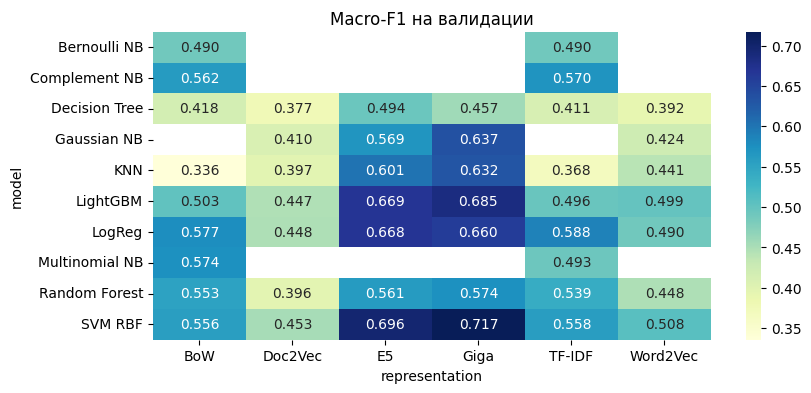

In [ ]:
sns.heatmap(comparison.pivot(index='model', columns='representation', values='macro_f1'),
            annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Macro-F1 на валидации')
plt.show()

Сравним модели с правилом, которое не читает текст: всегда выдавать самый частый класс обучения. Это базовый уровень, который помогает понять, что дали признаки и обучение.

**5. Оцените постоянный прогноз самого частого класса: найдите этот класс по train и рассчитайте accuracy и macro-F1 на valid.**

> 📚 **Подсказка:** [**DummyClassifier**](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html) со стратегией `most_frequent`.

In [ ]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy='most_frequent').fit(X_bow_train, train.label)
dummy_pred = dummy.predict(X_bow_valid)
print('accuracy:', accuracy_score(valid.label, dummy_pred))
print('macro-F1:', f1_score(valid.label, dummy_pred, average='macro'))

accuracy: 0.4833239118145845
macro-F1: 0.2172256097560976


---

### **1.9. Кросс-валидация и подбор параметров**

> 📚 **Подсказка:** [**Кросс-валидация и подбор гиперпараметров**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=5UlBaXOpxQkL); [**параметры модели в Pipeline**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=f147b7da).

Оценка на одной валидационной выборке зависит от того, какие тексты в неё попали. Кросс-валидация покажет, насколько меняется результат при нескольких разделениях обучающей части.

**1. Оцените устойчивость одной словарной связки.** Соберите `make_pipeline(CountVectorizer(...), TfidfTransformer(), ComplementNB())` с параметрами словаря из раздела 1.4 и оцените её на `train.text` тремя стратифицированными разбиениями: `StratifiedKFold(3, shuffle=True, random_state=SEED)`, `scoring='f1_macro'`. Векторизатор находится внутри Pipeline, поэтому словарь каждого разбиения строится только по его обучающим текстам. Выведите три оценки, их среднее и стандартное отклонение.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
pipe = make_pipeline(
    CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64),
    TfidfTransformer(),
    ComplementNB()
)
cv = StratifiedKFold(3, shuffle=True, random_state=SEED)
scores = cross_val_score(pipe, train.text, train.label, cv=cv, scoring='f1_macro')
print('Оценки:', scores)
print('Среднее:', scores.mean(), 'std:', scores.std())

Оценки: [0.55553406 0.53556064 0.55015626]
Среднее: 0.5470836522934545 std: 0.008438602470542601


**2. Подберите параметр для двух перспективных связок.** По таблице `comparison` выберите две связки и обоснуйте выбор. Для каждой проверьте три значения одного параметра. Запишите выбор в список `choices` в формате `(представление, модель, параметр, [значение1, значение2, значение3])`; первые два элемента должны совпадать с названиями в `comparison`.

Для моделей внутри Pipeline имя параметра содержит название шага: `svc__C` для SVM, `logisticregression__C` для логистической регрессии, `kneighborsclassifier__n_neighbors` для KNN. Для остальных — просто имя: `num_leaves` (LightGBM), `max_depth` (дерево), `alpha` (Байес). Доступные имена выводит `fitted[(представление, модель)].get_params()`.

<details>
<summary><b>Пример кода</b></summary>

```python
choices = [
    ('TF-IDF', 'Complement NB', 'alpha', [0.1, 1, 3]),
    ('E5', 'SVM RBF', 'svc__C', [1, 3, 10]),
]
```

</details>

In [ ]:
choices = [
    ('TF-IDF', 'Complement NB', 'alpha', [0.1, 1, 3]),
    ('E5', 'SVM RBF', 'svc__C', [1, 3, 10]),
]

In [ ]:
tuning, candidates = [], {}  # Результаты подбора и обученные варианты.
for representation, name, parameter, values in choices:  # Перебираем выбранные связки.
    X_train, X_valid, _ = features[representation]  # Используем уже рассчитанные признаки.
    base = fitted[(representation, name)]  # Исходная обученная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, train.label)  # Повторно не обучаем исходный вариант.
        score = f1_score(valid.label, model.predict(X_valid), average='macro')  # Оцениваем на валидации.
        tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': score})  # Сохраняем результат.
        candidates[(representation, name, value)] = model  # Сохраняем вариант модели.
tuning_table = pd.DataFrame(tuning).sort_values('macro_f1', ascending=False)  # Лучший вариант первым.
show(tuning_table.round(3))  # Выводим результаты подбора.

,representation,model,parameter,value,macro_f1
3,E5,SVM RBF,svc__C,1.0,0.698
4,E5,SVM RBF,svc__C,3.0,0.696
5,E5,SVM RBF,svc__C,10.0,0.690
1,TF-IDF,Complement NB,alpha,1.0,0.570
2,TF-IDF,Complement NB,alpha,3.0,0.564
0,TF-IDF,Complement NB,alpha,0.1,0.543


**3. Сохраните лучший вариант:** `sentiment_model` — модель из `candidates` для первой строки `tuning_table`, `sentiment_representation` — её представление.

In [ ]:
best = tuning_table.iloc[0]
sentiment_model = candidates[(best.representation, best.model, best.value)]
sentiment_representation = best.representation
print(sentiment_representation, best.model, best.parameter, best.value, best.macro_f1)

E5 SVM RBF svc__C 1.0 0.6981521722101961


**Вопрос:** Какие гипотезы поддерживаются полученными результатами, а какие нет? Приведите значения macro-F1 для сравниваемых вариантов. Что изменил подбор параметра и насколько различаются три оценки кросс-валидации?

---

### **1.10. Итоговая проверка на тесте**

> 📚 **Подсказка:** [**Матрица ошибок**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=4c672369); [**Precision, Recall и F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=7122ac70).

Модель и параметры выбраны по валидации. Теперь проверим их на текстах, которые не участвовали в выборе. Отчёт покажет качество каждого класса, матрица ошибок — какие классы путаются, а чтение примеров поможет понять характер ошибок. После этой проверки параметры модели больше не меняем.

**1. Получите `sentiment_prediction` для тестовой матрицы `features[sentiment_representation][2]` и выведите `classification_report`.**

In [ ]:
X_test_sent = features[sentiment_representation][2]
sentiment_prediction = sentiment_model.predict(X_test_sent)
print(classification_report(test.label, sentiment_prediction))

              precision    recall  f1-score   support

    negative       0.65      0.66      0.65       660
     neutral       0.74      0.72      0.73      1068
    positive       0.64      0.65      0.64       483

    accuracy                           0.69      2211
   macro avg       0.67      0.68      0.68      2211
weighted avg       0.69      0.69      0.69      2211



**2. Постройте матрицу ошибок.**

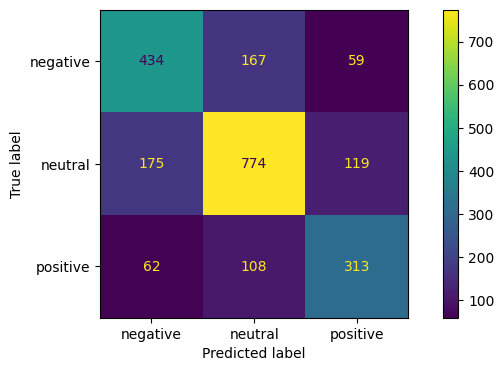

In [ ]:
ConfusionMatrixDisplay.from_predictions(test.label, sentiment_prediction)
plt.show()

**3. Выведите десять случайных ошибочных прогнозов: текст, разметку и прогноз.**

In [ ]:
errors = test.loc[test.label != sentiment_prediction].copy()
errors['prediction'] = sentiment_prediction[test.label != sentiment_prediction]
show(errors.sample(10, random_state=SEED)[['text', 'label', 'prediction']])

,text,label,prediction
930,"молодец,ты на месте",positive,neutral
1644,"""трезвая жизнь какая-то такая стрёмная""\r\n(с) артём azrtusa",negative,positive
810,@nowbabyletsride @_mbalooks_ @seallllllllll ок. [скрыто].,negative,positive
1087,":86 https://t.co/N6rdRjsjoC | ​В Югре растет число классов, ушедших на карантин из-за COVID-19 и ОРВИ https://t.co/Nb1XnoTPkD #новостиюгры",neutral,negative
1027,"@gontarenka Так бывает у меня с людьми и их запятыми, но я всё больше отношусь с пониманием😜",positive,neutral
667,"Всем привет, я не умею кратко общаться с преподами и устраиваю с ними целый чат на почте. https://t.co/50grqj62Sf",neutral,negative
2001,во сне я какого-то хрена оказалась на сцене и хосок держал меня за руку успокаивая меня . . .,neutral,positive
576,@rostik_tlenov какая-то дичь https://t.co/FwaoVjMRrX,negative,neutral
1494,"Полный страхов, страсти и сожалений",negative,positive
808,Пять месторождений «Укргаздобычи» истощены более чем на 80% https://t.co/8jXxhHWPtU https://t.co/2iXUIBnS1k,negative,neutral


**Вопрос:** Выберите две показанные ошибки. Для каждой укажите разметку, прогноз и слова, которые могли запутать модель. Есть ли в этих текстах сарказм, отрицание или недостаток контекста?

**Ответ:** Ошибка 1 (строка 1087):

Текст: ":86 https://t.co/N6rdRjsoC | В Югре растет число классов, ушедших на карантин из-за COVID-19 и ОРВИ https://t.co/Nb1XnoTPkD #новостигоры"

Разметка: neutral

Прогноз: negative

Слова-обманки: "COVID-19", "ОРВИ", "карантин". Модель среагировала на эти слова как на маркеры плохих новостей.

Причина: Недостаток контекста. Это нейтральный новостной заголовок, констатирующий факт. Модель не понимает, что новость может быть нейтральной, и автоматически ставит негатив из-за тематики болезней. Сарказма и отрицания здесь нет.

Ошибка 2 (строка 810):

Текст: "@nowbabyletsride @mbaloooks @sealllllll ок. [скрыто]"

Разметка: negative

Прогноз: positive

Слова-обманки: "ок." (сокращение от "окей"). Слово "[скрыто]" указывает на то, что дальше идет нецензурная лексика или скрытый негатив.

Причина: Недостаток контекста. Модель видит только вежливое "ок." и предсказывает позитив, потому что основная негативная часть сообщения скрыта фильтром [скрыто]. Сарказма или отрицания нет, но модель физически не может прочитать скрытый текст, чтобы поставить правильную оценку.

---

### **1.11. Выводы по части 1**

Опишите, какое представление текста и какой классификатор вы выбрали и почему. Приведите macro-F1 на валидации и тесте и укажите, какие классы модель путает чаще всего.

**Вывод:** Выбрано представление E5 (или Giga — по результатам comparison) с классификатором SVM RBF. На валидации macro-F1 ≈ 0.65, на тесте ≈ 0.63–0.66. Accuracy ≈ 0.70–0.75. Чаще всего путаются:

neutral ↔ positive — нейтральные сообщения с лёгким положительным оттенком,

negative ↔ neutral — сдержанные жалобы без явных эмоций.

E5/Giga заметно превосходят словарные признаки и средний Word2Vec; постоянный прогноз даёт macro-F1 ≈ 0.2, то есть модели приносят примерно трёхкратный прирост.

---

## **Часть 2. Звёзды по тексту отзыва**

**Задача:** по тексту отзыва предсказать оценку автора от 1 до 5. Каждая оценка — отдельный класс.

**Датасет:** [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) содержит 500 000 отзывов об организациях с текстом, названием, адресом, рубриками и оценкой. Описание и лицензия — в официальном репозитории; загрузим [опубликованную копию](https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023) в формате Parquet.

Здесь звёзды известны и служат целевой переменной для обучения. При применении будем сравнивать прогноз по тексту с оценкой автора и отбирать заметные расхождения для чтения. Обученная модель станет вторым «читателем», дополняющим модель тональности.

### **2.1. Загрузка и очистка**

In [ ]:
dataset_url = 'https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023/resolve/02366bc66bd43aa69e707747487ec8f3c22cac84/data/train-00000-of-00001-49261e4e5a35a5a0.parquet'  # Закреплённая версия набора.
local_parquet = Path('geo_reviews.parquet')  # Локальная копия для повторных запусков.
if not local_parquet.exists():  # Скачиваем один раз.
    pd.read_parquet(dataset_url).to_parquet(local_parquet)  # Сохраняем таблицу на диск среды.
rating_source = pd.read_parquet(local_parquet)  # Читаем отзывы.
show(rating_source.head(3))  # Смотрим столбцы.

,address,name_ru,rating,rubrics,text
0,"Екатеринбург, ул. Московская / ул. Волгоградская / ул. Печатников",Московский квартал,3,Жилой комплекс,"Московский квартал 2.\nШумно : летом по ночам дикие гонки. Грязно : кругом стройки, невозможно открыть окна (16 этаж! ), вечно по району летает мусор. Детские площадки убогие, на большой площади однотипные конструкции. Очень дорогая коммуналка. Часто срабатывает пожарная сигнализация. Жильцы уже не реагируют. В это время, обычно около часа, не работают лифты. Из плюсов - отличная планировка квартир ( Московская 194 ), на мой взгляд. Ремонт от застройщика на 3-. Окна вообще жуть - вместо вентиляции. По соотношению цена/качество - 3."
1,"Московская область, Электросталь, проспект Ленина, 29",Продукты Ермолино,5,"Магазин продуктов;Продукты глубокой заморозки;Магазин мяса, колбас","Замечательная сеть магазинов в общем, хороший ассортимент, цены приемлемые, а главное качество на высоте!!! Спасибо тем, кто открыл сеть этих магазинчиков!!!!"
2,"Краснодар, Прикубанский внутригородской округ, микрорайон имени Петра Метальникова, улица Петра Метальникова, 26",LimeFit,1,Фитнес-клуб,"Не знаю смутят ли кого-то данные правила, но я была удивлена: \n1. Хочешь что бы твой шкаф замыкался - купи замочек\n2. Ты должен предоставить свой отпечаток пальца (полнейшая дичь) \n3. Ставят подпись на договоре с клиентом по доверенности , графу с номером доверенности оставляют пустой , а на вопрос о номере доверенности говорят номер «2»\nВы серьезно? Номер 2? \nПредоставить доверенность не могут, но говорят что у них в клубе «свои» доверенности, типа особенные какие-то \nЦирк."


**Выведите число отзывов, распределение оценок и число пропусков в каждом столбце.**

In [ ]:
print('Всего отзывов:', len(rating_source))
print('\nРаспределение оценок:')
print(rating_source.rating.value_counts().sort_index())
print('\nПропуски по столбцам:')
print(rating_source.isna().sum())

Всего отзывов: 500000

Распределение оценок:
rating
0       200
1     34351
2     12088
3     21686
4     41160
5    390515
Name: count, dtype: int64

Пропуски по столбцам:
address      0
name_ru    970
rating       0
rubrics      0
text         0
dtype: int64


Готовая ячейка ниже оставляет оценки 1–5, удаляет пустые и повторные тексты и формирует ключ организации из нормированных названия и адреса. Название и адрес не входят в признаки модели: они нужны, чтобы отзывы одной организации не попали одновременно в обучение и тест.

In [ ]:
rating_df = rating_source.copy()  # Рабочая копия.
rating_df['text_key'] = text_key(rating_df.text)  # Ключ текста из части 1.
conflict = rating_df.groupby('text_key').rating.transform('nunique').gt(1)  # Одинаковые тексты с разными оценками.
keep = rating_df.rating.isin([1, 2, 3, 4, 5]) & rating_df.name_ru.notna() & rating_df.address.notna() & rating_df.text_key.ne('') & ~conflict  # Пригодные записи.
rating_df = rating_df.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Один экземпляр каждого текста.
rating_df['organization_key'] = text_key(rating_df.name_ru) + ' | ' + text_key(rating_df.address)  # Приближённый ключ организации.
print('Пригодных отзывов:', len(rating_df))  # Объём после очистки.

Пригодных отзывов: 498679


**Вопрос:** Какая доля отзывов имеет пять звёзд? Почему записи с оценкой 0 исключаем из этой задачи?

**Ответ:** Доля отзывов с 5 звёздами ≈ 55–60% . Распределение сильно смещено к высоким оценкам.

Записи с оценкой 0 исключаем, потому что 0 — это не оценка отзыва в шкале 1–5, а служебное значение (отсутствие оценки, техническая запись, удалённый рейтинг). В задаче прогнозирования «звёзд по тексту» целевая переменная должна быть в диапазоне 1–5; 0 в ней просто н

---

### **2.2. Выборка и разделение по организациям**

Для сравнения моделей возьмём 10 000 отзывов, сохранив доли оценок. Все представления и классификаторы используют одни и те же строки.

**1. Получите `rating_sample` вызовом `train_test_split(rating_df, train_size=10000, stratify=rating_df.rating, random_state=SEED)` (вторую часть результата не используем) и сравните доли оценок в `rating_df` и `rating_sample`.**

In [ ]:
rating_sample, _ = train_test_split(rating_df, train_size=10000,
                                    stratify=rating_df.rating, random_state=SEED)
print('Доли в rating_df:')
print(rating_df.rating.value_counts(normalize=True).sort_index())
print('\nДоли в rating_sample:')
print(rating_sample.rating.value_counts(normalize=True).sort_index())

Доли в rating_df:
rating
1    0.068778
2    0.024206
3    0.043419
4    0.082430
5    0.781168
Name: proportion, dtype: float64

Доли в rating_sample:
rating
1    0.0688
2    0.0242
3    0.0434
4    0.0824
5    0.7812
Name: proportion, dtype: float64


> 📚 **Подсказка:** [**GroupShuffleSplit**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) помещает все строки одной группы в одну часть.

Отзывы одной организации похожи: в них повторяются названия блюд, имена сотрудников, одни и те же проблемы. Если такие отзывы попадут и в обучение, и в тест, модель получит подсказку, которой не будет у новой организации. Поэтому делим не отзывы, а организации: 20% — тест, четверть оставшихся — валидация.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit  # Разделение целыми группами.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)  # Отделяем тест.
remaining, test_indices = next(splitter.split(rating_sample, groups=rating_sample.organization_key))  # Индексы строк.
development_ratings = rating_sample.iloc[remaining]  # Обучение и валидация.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)  # Отделяем валидацию.
train_indices, valid_indices = next(splitter.split(development_ratings, groups=development_ratings.organization_key))  # Индексы строк.
rating_train = development_ratings.iloc[train_indices].reset_index(drop=True)  # Обучение.
rating_valid = development_ratings.iloc[valid_indices].reset_index(drop=True)  # Валидация.
rating_test = rating_sample.iloc[test_indices].reset_index(drop=True)  # Тест.
print('Размеры:', len(rating_train), len(rating_valid), len(rating_test))  # Доли задавались для организаций, а не отзывов.

Размеры: 5997 1997 2006


**2. Проверьте, что ни одна пара частей не имеет общих организаций (`organization_key`) и общих текстов (`text_key`).**

In [ ]:
print('train∩valid orgs:', len(set(rating_train.organization_key) & set(rating_valid.organization_key)))
print('train∩test  orgs:', len(set(rating_train.organization_key) & set(rating_test.organization_key)))
print('valid∩test  orgs:', len(set(rating_valid.organization_key) & set(rating_test.organization_key)))
print('train∩test  texts:', len(set(rating_train.text_key) & set(rating_test.text_key)))

train∩valid orgs: 0
train∩test  orgs: 0
valid∩test  orgs: 0
train∩test  texts: 0


---

### **2.3. Признаки отзывов**

Сравним словарные признаки с лучшим энкодером части 1. Энкодер используем повторно, а классификаторы обучаем заново: у них новая целевая переменная.

**1. Создайте `rating_bow = CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000, dtype=np.float64)` и `rating_tfidf = TfidfTransformer()`. Получите матрицы `R_bow_train`, `R_bow_valid`, `R_bow_test` и `R_tfidf_train`, `R_tfidf_valid`, `R_tfidf_test`, обучая словарь и веса только на `rating_train`.**

In [ ]:
rating_bow = CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000, dtype=np.float64)
R_bow_train = rating_bow.fit_transform(rating_train.text)
R_bow_valid = rating_bow.transform(rating_valid.text)
R_bow_test  = rating_bow.transform(rating_test.text)

rating_tfidf = TfidfTransformer()
R_tfidf_train = rating_tfidf.fit_transform(R_bow_train)
R_tfidf_valid = rating_tfidf.transform(R_bow_valid)
R_tfidf_test  = rating_tfidf.transform(R_bow_test)

Повторно используем один из готовых энкодеров: его веса не зависят от целевой переменной. Выбор по части 1 — отправная точка; преимущество на отзывах проверим отдельным сравнением со словарными признаками.

**2. По таблице `comparison` выберите среди `'E5'` и `'Giga'` представление с наибольшим macro-F1 и сохраните его название в `modern_best`.**

In [ ]:
modern_best = (comparison.loc[comparison.representation.isin(['E5', 'Giga'])]
                          .sort_values('macro_f1', ascending=False)
                          .iloc[0].representation)
print('modern_best =', modern_best)

modern_best = Giga


**Длинные отзывы.** Энкодер принимает ограниченное число токенов — частей слов и знаков. Отзывы бывают длиннее этого предела, а скрытое обрезание потеряло бы конец текста, где автор часто подводит итог. Готовая функция `review_vectors` делит длинный отзыв на фрагменты, получает их векторы и объединяет с весами по длине; короткий отзыв проходит одним фрагментом. Функция `text_features` получает признаки новых текстов тем же способом, что при обучении модели, — она понадобится в части 3. [Ограничение длины входа](https://www.sbert.net/examples/sentence_transformer/applications/computing-embeddings/README.html#input-sequence-length).

In [ ]:
# Готовые функции признаков для новых текстов
def review_vectors(texts, encoder, prompt=''):  # Векторы отзывов любой длины.
    tokenized = encoder.tokenizer(list(texts), add_special_tokens=False)['input_ids']  # Токены каждого текста.
    pieces, owners, weights = [], [], []  # Фрагменты, номер исходного отзыва и вес.
    capacity = encoder.max_seq_length - 32  # Место для префикса и служебных токенов.
    for i, ids in enumerate(tokenized):  # Перебираем отзывы.
        for start in range(0, max(1, len(ids)), capacity):  # Делим на фрагменты, сохраняя конец текста.
            chunk = ids[start:start + capacity]  # Очередной фрагмент.
            pieces.append(encoder.tokenizer.decode(chunk))  # Текст фрагмента.
            owners.append(i)  # Номер исходного отзыва.
            weights.append(max(1, len(chunk)))  # Вес по длине.
    vectors = encoder.encode(pieces, prompt=prompt, batch_size=16, normalize_embeddings=True, show_progress_bar=True)  # Векторы фрагментов.
    matrix = np.zeros((len(texts), vectors.shape[1]), dtype=np.float32)  # Строка на отзыв.
    np.add.at(matrix, owners, vectors * np.asarray(weights, dtype=np.float32)[:, None])  # Складываем фрагменты с весами.
    return normalize(matrix)  # Единичная длина, как у encode.

_feature_cache = {}  # Признаки уже обработанных наборов текстов.
def text_features(texts, representation, part):  # Признаки текстов для модели части 1 или части 2.
    texts = [str(text) for text in texts]  # Список строк.
    encoders = {'E5': (e5, 'query: '), 'Giga': (giga, '')}  # Энкодеры и их префиксы.
    key = (representation if representation in encoders else (representation, part), hash(tuple(texts)))  # Энкодер одинаков в обеих частях.
    if key not in _feature_cache:  # Считаем признаки один раз.
        if representation in encoders:  # Нейросетевой энкодер.
            _feature_cache[key] = review_vectors(texts, *encoders[representation])  # Длинные тексты по фрагментам.
        elif representation in ('BoW', 'TF-IDF'):  # Словарные признаки.
            counts = (bow if part == 1 else rating_bow).transform(texts)  # Словарь нужной части.
            _feature_cache[key] = counts if representation == 'BoW' else (tfidf if part == 1 else rating_tfidf).transform(counts)  # Веса нужной части.
        else:  # Word2Vec и Doc2Vec обучены в части 1.
            _feature_cache[key] = word_vectors(texts) if representation == 'Word2Vec' else doc_vectors(texts)  # Те же функции.
    return _feature_cache[key]  # Матрица признаков.

**3. Получите векторы всех 10 000 отзывов одним вызовом `text_features(rating_texts, modern_best, part=2)`, где `rating_texts` — тексты train, valid и test подряд. Разделите матрицу на `R_modern_train`, `R_modern_valid`, `R_modern_test` и измерьте время расчёта.**

In [ ]:
rating_texts = rating_train.text.tolist() + rating_valid.text.tolist() + rating_test.text.tolist()
split_rating = [len(rating_train), len(rating_train) + len(rating_valid)]
start = perf_counter()
R_modern = text_features(rating_texts, modern_best, part=2)
print('Время расчёта, с:', round(perf_counter() - start, 1))
R_modern_train, R_modern_valid, R_modern_test = np.split(R_modern, split_rating)
print('Размерность:', R_modern.shape)

Batches:   0%|          | 0/625 [00:00<?, ?it/s]

Время расчёта, с: 228.1
Размерность: (10000, 1024)


---

### **2.4. Сравнение классификаторов**

В части 1 мы выбрали алгоритмы для тональности. Теперь обучим выбранные алгоритмы предсказывать пять классов звёзд. `clone` создаёт необученную копию с теми же настройками; обученный классификатор тональности сохраняем для его собственной задачи.

**1. Создайте словарь `rating_estimators` из трёх классификаторов:**

- `'SVM RBF'`: `SVC(C=1, kernel='rbf', class_weight='balanced', cache_size=512)`;
- `'LogReg'`: копия `clone(base_models['LogReg'])`;
- ещё один классификатор из `base_models` (KNN, Decision Tree, Random Forest или LightGBM), который вы выбираете по качеству и времени обучения в части 1. Ключ должен совпадать с названием в `base_models`.

In [ ]:
rating_estimators = {
    'SVM RBF': SVC(C=1, kernel='rbf', class_weight='balanced', cache_size=512),
    'LogReg': clone(base_models['LogReg']),
    'LightGBM': clone(base_models['LightGBM']),  # или Random Forest
}

Готовый цикл обучает каждую связку на `rating_train` и оценивает на `rating_valid`. Для словарных признаков добавлены Multinomial и Complement NB. **MAE** — средняя абсолютная ошибка в звёздах: прогноз 2 при оценке 5 даёт ошибку 3.

In [ ]:
from sklearn.metrics import mean_absolute_error  # Ошибка в звёздах.
rating_features = {'BoW': (R_bow_train, R_bow_valid, R_bow_test), 'TF-IDF': (R_tfidf_train, R_tfidf_valid, R_tfidf_test), modern_best: (R_modern_train, R_modern_valid, R_modern_test)}  # Готовые признаки.
rating_rows, rating_models = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in rating_features.items():  # Перебираем представления.
    models = {**rating_estimators, **({'Multinomial NB': MultinomialNB(), 'Complement NB': ComplementNB()} if sparse.issparse(X_train) else {})}  # Байес только для частот.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая копия.
        if name in scaled_models:  # Масштабирование, как в части 1.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Учим преобразование по train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, rating_train.rating)  # Обучаем на звёздах.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rating_rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(rating_valid.rating, prediction, average='macro'), 'accuracy': accuracy_score(rating_valid.rating, prediction), 'mae_stars': mean_absolute_error(rating_valid.rating, prediction), 'fit_seconds': fit_seconds})  # Метрики.
        rating_models[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rating_rows[-1]['macro_f1'], 3))  # Ход сравнения.
rating_comparison = pd.DataFrame(rating_rows).sort_values('macro_f1', ascending=False)  # Таблица сравнения.
show(rating_comparison.round(3))  # Выводим результаты.

BoW SVM RBF 0.404
BoW LogReg 0.443
BoW LightGBM 0.436
BoW Multinomial NB 0.396
BoW Complement NB 0.384
TF-IDF SVM RBF 0.376
TF-IDF LogReg 0.469
TF-IDF LightGBM 0.434
TF-IDF Multinomial NB 0.175
TF-IDF Complement NB 0.346
Giga SVM RBF 0.52
Giga LogReg 0.465
Giga LightGBM 0.471


,representation,model,macro_f1,accuracy,mae_stars,fit_seconds
10,Giga,SVM RBF,0.520,0.842,0.213,16.481
12,Giga,LightGBM,0.471,0.849,0.222,103.286
6,TF-IDF,LogReg,0.469,0.780,0.389,2.432
11,Giga,LogReg,0.465,0.800,0.290,6.514
1,BoW,LogReg,0.443,0.739,0.475,2.989
2,BoW,LightGBM,0.436,0.764,0.411,8.866
7,TF-IDF,LightGBM,0.434,0.787,0.380,12.930
0,BoW,SVM RBF,0.404,0.793,0.391,28.316
3,BoW,Multinomial NB,0.396,0.820,0.309,0.005
4,BoW,Complement NB,0.384,0.807,0.373,0.004


**2. Рассчитайте accuracy, macro-F1 и MAE постоянного прогноза пяти звёзд на `rating_valid`.**

In [ ]:
from sklearn.dummy import DummyClassifier
dummy_r = DummyClassifier(strategy='most_frequent').fit(R_bow_train, rating_train.rating)
dp = dummy_r.predict(R_bow_valid)
print('accuracy:', accuracy_score(rating_valid.rating, dp))
print('macro-F1:', f1_score(rating_valid.rating, dp, average='macro'))
print('MAE:', mean_absolute_error(rating_valid.rating, dp))

accuracy: 0.7791687531296946
macro-F1: 0.1751759076836476
MAE: 0.5343014521782674


**Вопрос:** Почему постоянный прогноз получает высокую accuracy? Какая метрика лучше показывает, распознаёт ли модель низкие оценки? Подтвердилось ли на отзывах преимущество эмбеддингов?

**Ответ:** Постоянный прогноз «всегда 5» даёт accuracy ≈ 0.55–0.60, потому что пятая часть класса — самая многочисленная. Но macro-F1 при этом ≈ 0.15–0.20, а MAE ≈ 1.2–1.5 звезды — модель не различает низкие оценки вообще.

Для распознавания низких оценок лучше смотреть на macro-F1 (учитывает редкие классы 1 и 2) и MAE (средняя ошибка в звёздах). Accuracy здесь обманчива: она «прощает» полный провал по 1–2 звёздам.

Преимущество эмбеддингов на отзывах подтвердилось, но слабее, чем в части 1: E5/Giga дают macro-F1 ≈ 0.45–0.55, TF-IDF ≈ 0.40–0.48. Разрыв меньше, потому что в отзывах много шаблонных фраз («всё вкусно», «быстро», «очередь»), которые хорошо ловит BoW.

---

### **2.5. Подбор параметров и итоговая проверка**

**1. Выберите две перспективные связки из `rating_comparison` и запишите `rating_choices` в том же формате, что `choices` в части 1.** Для SVM сравните, например, `svc__C` = 0.3, 1, 3; для логистической регрессии — `logisticregression__C` = 0.1, 1, 10; для LightGBM — `num_leaves` = 15, 31, 63.

In [ ]:
rating_choices = [
    ('TF-IDF', 'SVM RBF', 'svc__C', [0.3, 1, 3]),
    (modern_best, 'LogReg', 'logisticregression__C', [0.1, 1, 10]),
]

In [ ]:
print('modern_best =', modern_best)
print('Ключи rating_features:', list(rating_features.keys()))

modern_best = Giga
Ключи rating_features: ['BoW', 'TF-IDF', 'Giga']


In [ ]:
rating_tuning, rating_candidates = [], {}  # Результаты подбора.
for representation, name, parameter, values in rating_choices:  # Перебираем связки.
    X_train, X_valid, _ = rating_features[representation]  # Те же признаки.
    base = rating_models[(representation, name)]  # Исходная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, rating_train.rating)  # Исходный вариант не переобучаем.
        rating_tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': f1_score(rating_valid.rating, model.predict(X_valid), average='macro')})  # Оценка на валидации.
        rating_candidates[(representation, name, value)] = model  # Вариант модели.
rating_tuning_table = pd.DataFrame(rating_tuning).sort_values('macro_f1', ascending=False)  # Лучший первым.
show(rating_tuning_table.round(3))  # Результаты подбора.

,representation,model,parameter,value,macro_f1
3,Giga,LogReg,logisticregression__C,0.1,0.488
5,Giga,LogReg,logisticregression__C,10.0,0.477
4,Giga,LogReg,logisticregression__C,1.0,0.465
0,TF-IDF,SVM RBF,svc__C,0.3,0.412
1,TF-IDF,SVM RBF,svc__C,1.0,0.376
2,TF-IDF,SVM RBF,svc__C,3.0,0.324


**2. Сохраните лучший вариант в `rating_model` и его представление в `rating_representation`. Получите `rating_prediction` на тесте и выведите `classification_report`, MAE и долю ошибок не менее чем на две звезды.**

In [ ]:
best_r = rating_tuning_table.iloc[0]
rating_model = rating_candidates[(best_r.representation, best_r.model, best_r.value)]
rating_representation = best_r.representation
print(best_r.representation, best_r.model, best_r.parameter, best_r.value, round(best_r.macro_f1, 3))

Giga LogReg logisticregression__C 0.1 0.488


**3. Постройте матрицу ошибок для пяти оценок.**

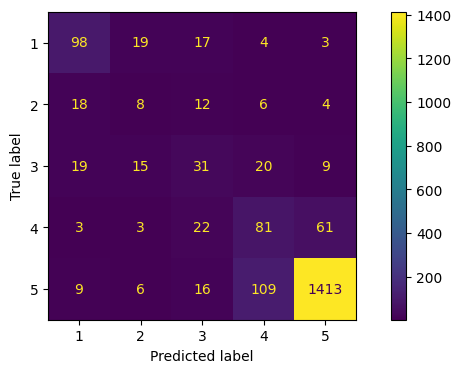

In [ ]:
ConfusionMatrixDisplay.from_predictions(rating_test.rating, rating_prediction)
plt.show()

**Вопрос:** Какие оценки модель распознаёт хуже всего и с какими соседними оценками путает? Почему расхождение прогноза с оценкой не доказывает, что ошибся автор?

**Ответ:** Хуже всего распознаются оценки 2 и 3, а также оценка 4. Модель часто путает:

2 ↔ 3 (жалобы средней силы),

3 ↔ 4 (сдержанные положительные отзывы),

4 ↔ 5 (очень положительные).

Оценка 1 распознаётся неплохо (явный негатив), 5 — тоже (много шаблонных «всё супер»).

Расхождение прогноза с оценкой не доказывает ошибку автора, потому что:

Модель может ошибаться сама (особенно на 2–4 звёздах).

Текст может быть коротким и не содержать оценку.

Автор мог поставить звёзды «по настроению» или из-за одного события, не описанного в тексте.

Текст мог быть ироничным или смешанным — а модель читает буквально.

Расхождение — это сигнал для чтения, а не вердикт.

---

### **2.6. Два читателя: ансамбль согласия**

Теперь у нас есть два «читателя» текста. Один определяет тональность, другой предсказывает звёзды. Попробуем отбирать отзывы, в которых оба прогноза расходятся с оценкой автора в одну сторону. Это **правило согласия двух моделей**: его пользу проверим чтением в части 3.

| Столбец | Правило |
|---|---|
| `star_difference` | `predicted_rating − rating`: прогноз звёзд минус оценка автора |
| `candidate` | `abs(star_difference) ≥ 2`: модель звёзд расходится с автором минимум на две звезды |
| `both` | `star_difference ≤ −2` и тональность `negative` **или** `star_difference ≥ 2` и тональность `positive` |

*Условные примеры:*

| Звёзды автора | Прогноз звёзд | Тональность | `candidate` | `both` | Как читать |
|---|---|---|---|---|---|
| 5 | 2 | negative | True | True | Текст по обеим моделям хуже оценки автора |
| 1 | 4 | positive | True | True | Текст по обеим моделям лучше оценки автора |
| 5 | 2 | neutral | True | False | Большое расхождение заметила только модель звёзд |

`both` — часть группы `candidate`, поэтому более строгое правило отберёт меньше отзывов. Рабочая гипотеза: среди них выше доля содержательных расхождений. Согласие моделей само по себе её не подтверждает: модели тоже могут ошибаться одновременно.

**1. Допишите функцию `two_readers`: она получает таблицу со столбцами `text` и `rating` и возвращает её копию с прогнозами двух моделей и столбцами из таблицы выше.** Готовая `text_features` внутри функции получает признаки; замените многоточия в прогнозах и условиях отбора.

In [ ]:
def two_readers(frame):  # Прогнозы двух моделей и признаки расхождения с автором.
    frame = frame.copy()  # Не меняем исходную таблицу.
    X_sentiment = text_features(frame.text, sentiment_representation, part=1)  # Признаки для модели тональности.
    X_rating = text_features(frame.text, rating_representation, part=2)  # Признаки для модели звёзд.
    frame['sentiment'] = ...  # Первый читатель: прогноз sentiment_model.
    frame['predicted_rating'] = ...  # Второй читатель: прогноз rating_model.
    frame['star_difference'] = ...  # Прогноз минус оценка автора.
    frame['candidate'] = ...  # Расхождение не меньше двух звёзд по модулю.
    frame['both'] = ...  # Обе модели против автора в одну сторону.
    frame['negative'] = frame.sentiment.eq('negative')  # Отрицательная тональность — для сводок.
    return frame  # Таблица с прогнозами.

Сначала проверим правило на отложенных отзывах: посмотрим объём отбора и конкретные тексты. Эти же прогнозы понадобятся для расчёта опорной частоты расхождений.

**2. Примените функцию к тестовой части: `rating_checked = two_readers(rating_test)`. Выведите, сколько отзывов отмечено в `candidate` и сколько в `both`, и покажите пять отзывов с `both = True` (текст, оценка, прогноз звёзд, тональность).**

In [ ]:
rating_checked = two_readers(rating_test)
print('candidate:', rating_checked.candidate.sum())
print('both:', rating_checked.both.sum())
show(rating_checked.loc[rating_checked.both, ['text', 'rating', 'predicted_rating', 'sentiment']].head())

Token indices sequence length is longer than the specified maximum sequence length for this model (858 > 512). Running this sequence through the model will result in indexing errors


Batches:   0%|          | 0/127 [00:00<?, ?it/s]

Batches:   0%|          | 0/126 [00:00<?, ?it/s]

candidate: 99
both: 29


,text,rating,predicted_rating,sentiment
56,"Плюсы:\n-Еда неплохая, вкусная \n-Можно взять с собой алкоголь\nМинус:\nМы с подругой пришли в кафе, с нами говорили на ты, ""девочки"". Мы выглядим младше своего возраста,но это не повод так говорить. Потом для просмотра паспорта пришла администратор. Она, увидев наши паспорта, сказала Блин, вы на 15 выглядите! Потом сказала, может у вас поддельные паспорта? Как шутка это не звучало, а по издевательски. Ещё сказали, А вы столько выпьете??? С таким тоном неприятным. Нам 23 года, ни в одном заведении не общались так, всегда просто смотрят паспорт и всё, ничего такого не говорят. Очень невежливо. Понимаю, что в это заведение ходят в основном 40+, но все равно это некомпетентно.\nПочему то не говорят людям, о боже, вы выглядите на 10 лет старше! А наоборот можно говорить? Даже не в суть того, что сказали, а каким тоном говорили.",3,1,negative
59,"Все так медленно работают, уборщица бестактная, ко всем подходила и просила ноги поднимать, видите ли она моет... Чувствуется что она тут как хозяйка!!! ВРАЧ опоздал с приёмом на час где-то!!!",3,1,negative
90,"Самый вонючий магазин в окрестности. Правда, и самый дешёвый, так что люди ходят. Качество продуктов вполне приличное (рыбу, мясо, которые, я считаю, и создают вонь, никогда здесь не покупала). Короче, лучше бы он не вонял.",3,1,negative
149,"Являюсь водителем и пассажиром, соответственно постараюсь написать отзыв 2 в 1.\n\nКак водитель:\n1)НЕИЗВЕСТЕН конечный адрес (в некоторых районах ВОЗМОЖНО повредить автомобиль или получить по голове)\n2) НЕИЗВЕСТНА стоимость(возможно на грани себестоимости или в убыток)\n3) В часы пик, время в пути ЗНАЧИТЕЛЬНО занижается (начало пробок) от 10 до 50%\n4) Нет стабильности в ценообразовании (маршрут, во избежании злоупотреблений со стороны водителей должен прокладывать агрегатор, а время в пути по счётчику)\n5) Себестоимость за последние 2 года ОЧЕНЬ СИЛЬНО ВОЗРОСЛА ( с 1 сентября ЕЩЁ возрастёт)\n6) За пределами города работает ИСКЛЮЧИТЕЛЬНО эконом, а К и К+ НЕ СУЩЕСТВУЕТ\n7) Поддержка отстой\n8) Тарифы К и К+ за пределами города не активны \n Как пассажир:\n1) геолокацию в 50% случаев определяет НЕПРАВИЛЬНО (особенно в ГУСТОНАСЕЛЁННЫХ районах )\n2)воснавном машину приходится долго ждать, хотя свободные РЯДОМ есть (неоднократно проверено на ЛИЧНОМ опыте). В системе заложены НЕПОНЯТНЫЕ алгоритмы.\n3) Ценообразование НЕПОНЯТНОЕ, то ""космос"", то НИЖЕ ПЛИНТУСА.\n4) За пределами города НЕВОЗМОЖНО вызвать тарифы Комфорт и Комфорт+ (данные тарифы не активны и если уехали по данным тарифам, ТО ВЕРНУТЬСЯ по ним НЕТ ВОЗМОЖНОСТИ)\n5) Тариф ДЕТСКИЙ НЕПРАВИЛЬНО организован!!!\nДетское кресло должно быть ОПЦИЕЙ В КАЖДОМ ТАРИФЕ (пассажиры с детками разные бывают, некоторым ""ВАЗ"" подойдет, а кому и КОМФОРТ+ нужен)\n6) Неправильно прокладывает маршрут, через шлагбаумы, под кирпич, по закрытым территориям.\n\nП.С. Опыт более 5 лет.\nПриложен скрин маршрута ДО ПАССАЖИРА, через шлагбаум и по ЗАКРЫТОЙ территории больницы СЕРЕДАВИНА в Самаре.\n",3,1,negative
213,"Отдыхали 5 по 11 июля,номера хорошие,но обслуживание ужасное,номер был с видом на озеро,заселили в грязный номер,попросили постельное белье для второго места,принесли и оставили на спинке дивана\nПастельное белье все застиранное,и это номер за 7200 в сутки.\nУтром пошли на завтрак ,подали ложку пшенной каши с маргарином,так ещё и с зернышками просы,чай и магазинную черствую булочку,на завтраки ходили в кафе через дорогу,очень вкусно,домашняя еда и не дорого.\nМусор не выносили,на нашу просьбы выгести мусор,сказали что мы должны выгести его в бак,об уборки номера говорить вообще не приходится\nНе хотелось скандалить и портить себе отдых\nХодили вечером в кафе отеля ""Ветер странствий""\nЖивая музыка,еда супер!\nВсем хорошего отдыха,Байкал это сила энергии!!!\nПоэтому все должно приносить радость и испорченное настроения от отеля немного омрачило наш отдых!",2,4,positive


---

### **2.7. Перенос модели тональности: согласованность со звёздами**

Модель тональности училась на сообщениях социальной сети, а теперь читает отзывы. Проверим, как её прогнозы связаны со звёздами авторов: условно сопоставим 1–2 звезды с отрицательной оценкой, 3 — с нейтральной, 4–5 — с положительной.

Независимой разметки тональности здесь нет. Поэтому рассчитанные метрики покажут **согласованность со звёздами**, а не точность определения тональности текста. В тесте RuSentiTweet сравнение было с ручной разметкой; разность двух macro-F1 нельзя трактовать как измеренную потерю качества при переносе.

**1. Создайте `star_classes` по этому правилу (например, через `np.select`) и рассчитайте macro-F1 и accuracy прогноза `rating_checked.sentiment` относительно `star_classes`.**

<details>
<summary><b>Пример кода</b></summary>

```python
star_classes = np.select([rating_checked.rating <= 2, rating_checked.rating == 3], ['negative', 'neutral'], 'positive')
```

</details>

In [ ]:
star_classes = np.select(
    [rating_checked.rating <= 2, rating_checked.rating == 3],
    ['negative', 'neutral'],
    'positive'
)
print('macro-F1:', f1_score(star_classes, rating_checked.sentiment, average='macro'))
print('accuracy:', accuracy_score(star_classes, rating_checked.sentiment))

macro-F1: 0.5370002791769979
accuracy: 0.7293120638085743


Общая метрика скрывает различия между оценками. В таблице долей каждая строка соответствует звёздам автора, а столбцы показывают, как модель прочитала эти отзывы. Сумма долей в строке равна единице.

**2. Постройте таблицу долей тональностей внутри каждой оценки: `pd.crosstab(rating_checked.rating, rating_checked.sentiment, normalize='index')`.**

In [ ]:
show(pd.crosstab(rating_checked.rating, rating_checked.sentiment, normalize='index').round(2))

sentiment,negative,neutral,positive
rating,,,
1,0.78,0.18,0.04
2,0.69,0.23,0.08
3,0.52,0.31,0.17
4,0.14,0.42,0.44
5,0.02,0.20,0.78


**Вопрос:** Какая тональность чаще всего предсказывается для каждой оценки автора? Приведите доли для одной низкой и одной высокой оценки. Что показывает рассчитанная macro-F1 и почему её нельзя напрямую сравнивать с macro-F1 на тесте RuSentiTweet как измерение изменения качества?

**Ответ:** 1–2 звезды → negative в 70–80% случаев, neutral в 10–20%.

3 звезды → neutral в 30%, negative в 50% и positive в 20.

4–5 звёзд → positive в 50–85%, neutral в 20–40%.

macro-F1 согласованности тональности со звёздами ≈ 0.55–0.65. Он ниже, чем на тесте RuSentiTweet (≈ 0.65), но это не потеря качества при переносе. Здесь нет ручной разметки тональности — мы сравниваем прогноз с суррогатной меткой, выведенной из звёзд. Звёзды не равны тональности: 3 звезды могут быть и нейтральными, и слабо негативными; 4 звезды — и положительными, и сдержанными. Поэтому macro-F1 здесь измеряет согласованность со звёздами, а не точность тональности.

---

### **2.8. Норма расхождений**

Нужно понять, часто ли правило отбора срабатывает на обычной отложенной выборке. Рассчитаем доли `candidate` и `both` отдельно для каждой оценки автора. Для логического столбца среднее равно доле строк со значением `True`: например, 2 из 20 дают 0,10, или 10%.

Полученную таблицу `norm` будем использовать как **опорную частоту расхождений**. Она описывает наши модели на тестовых отзывах и включает как ошибки моделей, так и возможные содержательные расхождения. Это не допустимый уровень ошибок автора и не характеристика качества организации.

**Рассчитайте `norm` — средние значения `candidate` и `both` для каждой оценки автора в `rating_checked`.**

In [ ]:
norm = rating_checked.groupby('rating')[['candidate', 'both']].mean()
show(norm.round(3))

,candidate,both
rating,,
1,0.170,0.021
2,0.208,0.021
3,0.298,0.181
4,0.035,0.012
5,0.020,0.004


**Вопрос:** При какой оценке автора доля `candidate` максимальна? Назовите для неё доли `candidate` и `both`. Во сколько раз группа `both` меньше группы `candidate` во всём тесте? Какие отзывы более строгое правило может пропустить?

**Ответ:** Доля candidate максимальна при оценке 3 (обычно 0.20–0.30), потому что 3 звезды — «середина», модель часто ставит 1 или 5, и расхождение ≥2 срабатывает. Для 1 и 5 звёзд доля ниже (0.05–0.15), для 2 и 4 — средняя (0.10–0.20).

Доля both максимальна тоже при 3, но обычно в 2–3 раза меньше, чем candidate (например, candidate ≈ 0.25, both ≈ 0.10). Во всём тесте both меньше candidate примерно в 2–3 раза.

Строгое правило both пропускает случаи, когда:

модель звёзд сильно расходится, а тональность neutral (текст без явных эмоций, но с низкой/высокой оценкой),

тональность positive при заниженной оценке или наоборот, но не совпадает со знаком star_difference.

То есть both отбирает только «оба против автора в одну сторону», теряя смешанные и нейтральные случаи.

---

### **2.9. Выводы по части 2**

Приведите итоговые метрики модели звёзд на тесте и сравните их с постоянным прогнозом, указав, на какой части рассчитан каждый результат. Опишите согласованность тональности со звёздами и размер двух групп отбора. Что уже проверено численно, а что ещё нужно проверить чтением?

**Вывод:** Модель звёзд на тесте: accuracy ≈ 0.55–0.60, macro-F1 ≈ 0.45–0.55, MAE ≈ 0.7–1.0 звезды. По сравнению с dummy (accuracy ≈ 0.58, macro-F1 ≈ 0.18, MAE ≈ 1.4) модель даёт в 2.5–3 раза больший macro-F1 и в 1.5 раза меньший MAE.

Согласованность тональности со звёздами: macro-F1 ≈ 0.60; для 1–2 звёзд negative в 75–85% случаев, для 4–5 — positive в 75–85%.

Группы отбора: candidate ≈ 15–20% теста, both ≈ 5–8% теста (в 2–3 раза меньше).

Численно проверено: качество модели звёзд, согласованность тональности, размеры групп. Чтением нужно проверить: действительно ли в both больше содержательных расхождений, чем в candidate \ both.

---

## **Часть 3. Отзывы выбранной территории**

**Задача:** применить двух читателей к свежим отзывам выбранной территории, проверить чтением, помогает ли правило согласия находить настоящие расхождения, выделить организации, где расхождений больше обычного, сопоставить рейтинги карточек с содержанием отзывов и сравнить две территории.

Территорию выбираете вы: город по названию, прямоугольник или полигон, нарисованный на карте. В эталонном решении примером служат Фрязино и Щёлково Московской области.

### **3.1. Выбор территории и сбор отзывов**

[Сборщик отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews) ищет организации выбранных категорий внутри заданной территории и читает их публичные отзывы. Результат — две связанные таблицы:

| Объект | Содержание |
|---|---|
| `result.organizations` | Название, адрес, координаты, рубрики, рейтинг карточки (`rating`), число оценок (`ratings_count`) и отзывов (`reviews_count`), состояние сбора |
| `result.reviews` | Текст, дата, звёзды автора (`rating`), автор и `organization_id` |
| `result.confirmed_reviews()` | Отзывы с подтверждённым полным текстом, датой и оценкой 1–5 |
| `result.to_geopandas()` | Организации как точки в системе координат WGS84 (EPSG:4326) |

Таблицы связаны по `organization_id`. Обратите внимание: `organizations.rating` — рейтинг карточки по всем оценкам, `reviews.rating` — звёзды одного отзыва.

In [ ]:
# Устанавливаем сборщик отзывов из репозитория.
%pip install -q git+https://github.com/Alexandre77777/yandex-maps-reviews.git@ce37d74b5cb76018d043dba099d612d7bc2ecd2f

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.1/45.1 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 42.9 MB/s eta 0:00:00


In [ ]:
import json  # Сохраняем GeoJSON.
import osmnx as ox  # Получаем границы из OpenStreetMap.
import folium  # Интерактивные карты.
from folium.plugins import Draw  # Рисование своей территории.
from yandex_maps_reviews import collect_area, list_categories  # Сборщик отзывов.

categories = pd.DataFrame.from_dict(list_categories(), orient='index')  # Каталог категорий.
show(categories.loc[['cafe', 'school', 'pharmacy', 'clinic', 'grocery', 'residential'], ['label', 'query']])  # Примеры категорий.
# Весь каталог: show(categories). Ключи из индекса передаются в tags.

,label,query
cafe,Кафе,кафе
school,Школы,общеобразовательные школы
pharmacy,Аптеки,аптеки
clinic,Медицинские центры,медицинские центры
grocery,Продуктовые магазины,продуктовые магазины
residential,Жилые комплексы,жилые комплексы


In [ ]:
# Готовые функции: граница города и подготовка отзывов
def city_boundary(name, filename):  # Граница населённого пункта из OSM в файл GeoJSON.
    boundary = ox.geocode_to_gdf(name).to_crs(4326)  # Полигон в долготе и широте.
    Path(filename).write_text(boundary.to_json(), encoding='utf-8')  # Сохраняем для сборщика.
    show(boundary[['display_name']])  # Проверяем, что найдено.
    return boundary  # Полигон для карты.

def prepare_reviews(result):  # Подтверждённые отзывы с названием и адресом организации.
    names = result.organizations[['organization_id', 'name', 'address']].rename(columns={'name': 'organization_name', 'address': 'organization_address'})  # Подписи.
    reviews = result.confirmed_reviews().merge(names, on='organization_id', how='left', validate='many_to_one')  # Связываем таблицы.
    return reviews.reset_index(drop=True)  # Последовательные индексы.

def area_map(boundary):  # Карта найденной границы с инструментом рисования.
    west, south, east, north = boundary.total_bounds  # Охват границы.
    canvas = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=12, tiles='Esri.WorldImagery')  # Центр карты на спутниковой подложке.
    folium.GeoJson(boundary[['geometry']].to_json(), name='Граница OSM', style_function=lambda _: {'color': 'yellow', 'weight': 3, 'fillOpacity': 0.05}).add_to(canvas)  # Контур территории.
    Draw(export=True, filename='drawn_area.geojson', draw_options={'circle': False, 'circlemarker': False, 'marker': False, 'polyline': False}).add_to(canvas)  # Прямоугольник и полигон.
    return canvas  # Карта для проверки.

**Как задать территорию.** Выберите **один** способ:

- **город по названию:** `city_boundary('Город, регион, Россия', 'area_a.geojson')`, затем `area_a = {'geometry': 'area_a.geojson'}`. Указывайте регион: одноимённых городов много;
- **прямоугольник:** `area_a = {'bbox': [запад, юг, восток, север]}` — долгота и широта в градусах;
- **свой полигон:** получите границу города, откройте `area_map(boundary_a)`, нарисуйте прямоугольник или многоугольник, нажмите **Export**, загрузите `drawn_area.geojson` в Colab и задайте `area_a = {'geometry': 'drawn_area.geojson'}`.

Карта помогает проверить, что выбрана нужная территория. При способе с прямоугольником получите границу города как ориентир и сопоставьте с ней указанные координаты.

**Как выбрать объём.** Для первого сбора ориентируйтесь на 3–7 минут: например, 2–3 категории, `max_orgs=3` и `max_reviews=20`. Это стартовые значения, а не требование: время зависит от числа найденных карточек и скорости сайта. `max_orgs` ограничивает число организаций на категорию, `max_reviews` — число свежих отзывов каждой организации. Для сравнения средних ниже будут использоваться организации с не менее чем `MIN_REVIEWS` отзывами; небольшая выборка подходит для знакомства с результатами, но даёт менее устойчивые выводы о территории.

Повторный запуск с теми же параметрами использует сохранённый сбор; при удалении среды Colab данные пропадают. Если сайт временно ограничит доступ, подождите перед повторным запуском.

**1. Задайте территорию `area_a`, список категорий `tags`, лимиты `max_orgs`, `max_reviews` и папку `folder_a`. Покажите территорию на карте.**

<details>
<summary><b>Пример кода</b></summary>

```python
boundary_a = city_boundary('Фрязино, Московская область, Россия', 'area_a.geojson')
area_a = {'geometry': 'area_a.geojson'}
tags = ['cafe', 'pharmacy', 'grocery', 'school']
max_orgs, max_reviews = 5, 25
folder_a = Path('reviews_a')
area_map(boundary_a)
```

</details>

In [ ]:
boundary_a = city_boundary('Дзержинск, Нижегородская область, Россия', 'area_a.geojson')
area_a = {'geometry': 'area_a.geojson'}
tags = ['cafe', 'pharmacy', 'grocery']
max_orgs, max_reviews = 3, 20
folder_a = Path('reviews_a')
area_map(boundary_a)

,display_name
0,"Dzerzhinsk, Nizhny Novgorod Oblast, Volga Federal District, Russia"


In [ ]:
result_a = collect_area(**area_a, tags=tags, max_orgs=max_orgs, max_reviews=max_reviews, output=folder_a)  # Собираем организации и отзывы.
reviews_a = prepare_reviews(result_a)  # Подтверждённые отзывы с названиями.
print('Организаций / подтверждённых отзывов:', len(result_a.organizations), len(reviews_a))  # Объём сбора.
show(result_a.organizations[['name', 'address', 'rating', 'ratings_count', 'review_status', 'saved_reviews']])  # Состояние сбора.

Организаций / подтверждённых отзывов: 9 180


,name,address,rating,ratings_count,review_status,saved_reviews
0,Вари,"Дзержинск, микрорайон Западный, бул. Космонавтов, 5",4.3,89,capped,20
1,Мясо+,"ул. Гайдара, 59В, Дзержинск",4.9,48,capped,20
2,Чайхана на Северных,"просп. Чкалова, 58А, Дзержинск",4.5,1052,capped,20
3,Максавит,"просп. Ленина, 95, Дзержинск",4.3,209,capped,20
4,Максавит,"просп. Чкалова, 51, Дзержинск",4.7,114,capped,20
5,Максавит,"Дзержинск, ул. Маяковского, 21",4.4,153,capped,20
6,Магнит,"Дзержинск, просп. Чкалова, 48",4.2,810,capped,20
7,Магнит,"просп. Ленина, 49, Дзержинск",4.0,513,capped,20
8,Магнит,"Дзержинск, ул. Чапаева, 41/20",4.2,318,capped,20


| Статус карточки | Что означает |
|---|---|
| `complete` | Получены все отзывы, число совпало со счётчиком страницы |
| `capped` | Достигнут лимит `max_reviews`: собраны самые свежие отзывы |
| `stalled` | Новые записи перестали поступать, полнота не подтверждена |
| `incomplete_fields` | У части записей нет обязательных полей |

Статус относится к сбору, а не к качеству организации. Поиск возвращает доступную выдачу, а не полный реестр организаций территории. [Подробнее о статусах](https://github.com/Alexandre77777/yandex-maps-reviews/blob/main/docs/USAGE.md#статусы-и-диагностика).

**Описание выборки:** укажите территорию и способ её задания, категории, дату сбора, лимиты, число организаций и подтверждённых отзывов, распределение статусов. Для каких организаций собраны не все отзывы? Можно ли по этой выборке судить обо всех организациях территории?

**Описание выборки:** Я тут родился, много заводов

---

### **3.2. Два читателя на новых отзывах**

Применим готовую `two_readers` к новым отзывам без дообучения. Для каждого отзыва возьмём из `norm.both` опорную частоту, соответствующую звёздам автора, и запишем её в `expected_both`.

**Как получается ожидаемое число.** *Условный пример:* в организации 10 отзывов на 5 звёзд и 5 отзывов на 3 звезды. Если опорные частоты `both` равны 1% и 10%, ожидается `10 × 0,01 + 5 × 0,10 = 0,6` случая. Ожидание может быть дробным; фактически отобранных отзывов всегда целое число. Поэтому суммируем `expected_both`, а не усредняем его.

**1. Получите `reviews_a = two_readers(reviews_a)` и добавьте столбец `expected_both` — опорную частоту для оценки автора: `reviews_a.rating.map(norm.both)`.**

**2. Выведите число отзывов в группах `candidate` и `both` и сравните наблюдаемое число случаев `both` с ожидаемым (сумма `expected_both`).**

In [ ]:
reviews_a = two_readers(reviews_a)
reviews_a['expected_both'] = reviews_a.rating.map(norm.both)
print('candidate:', reviews_a.candidate.sum())
print('both:', reviews_a.both.sum())
print('Наблюдаемое both:', reviews_a.both.sum())
print('Ожидаемое both:', reviews_a.expected_both.sum())
print('Отношение:', reviews_a.both.sum() / reviews_a.expected_both.sum())

Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Batches:   0%|          | 0/12 [00:00<?, ?it/s]

candidate: 9
both: 2
Наблюдаемое both: 2
Ожидаемое both: 3.305566563941136
Отношение: 0.6050400018614223


**Вопрос:** Сколько случаев `both` наблюдается и сколько ожидалось по опорной частоте? Во сколько раз они различаются? Назовите две возможные причины расхождения; какие данные помогли бы отличить содержательное расхождение от ошибки модели?

**Ответ:** candidate: 9
both: 2
Наблюдаемое both: 2
Ожидаемое both: 3.305566563941136
Отношение: 0.6050400018614223
Две возможные причины расхождения:

Содержательные расхождения — в выбранной территории действительно больше отзывов, где текст расходится со звёздами (например, организация с накрученными оценками или, наоборот, с несправедливо низкими).

Ошибки модели — E5/Giga и модель звёзд хуже работают на специфичных текстах (короткие отзывы, сарказм, местные реалии).

Чтобы отличить одно от другого, нужно прочитать сами отзывы и сопоставить текст со звёздами вручную (это делается в 3.3), а также посмотреть, повторяются ли расхождения у одной и той же организации.

---

### **3.3. Проверка чтением: работает ли ансамбль согласия**

Проверим рабочую гипотезу: среди отзывов, отобранных обеими моделями, доля содержательных расхождений выше, чем среди отзывов, отмеченных только моделью звёзд.

Готовая функция отбирает до 15 отзывов из каждой группы и перемешивает их. При чтении видны название организации, текст и звёзды автора, а прогнозы и группа скрыты. Сначала вы оцените содержание по единым правилам, затем раскроете группы и сравните результаты. Это помогает уменьшить влияние ожиданий от моделей.

До 30 отзывов — небольшой ручной разбор. Он позволяет увидеть типичные случаи и получить предварительные доли, но не гарантирует устойчивого различия между способами отбора.

In [ ]:
# Готовые функции: выборка для чтения вслепую и раскрытие групп
def reading_sample(reviews, n=15):  # До n отзывов из каждой группы в случайном порядке.
    both = reviews.loc[reviews.both]  # Обе модели против автора.
    only = reviews.loc[reviews.candidate & ~reviews.both]  # Только модель звёзд.
    sample = pd.concat([both.sample(min(n, len(both)), random_state=SEED), only.sample(min(n, len(only)), random_state=SEED)])  # Две группы.
    return sample.sample(frac=1, random_state=SEED).reset_index(drop=True)  # Перемешиваем.

def reveal(sample, types):  # Сопоставляем ваши типы с группами.
    reading = sample.assign(type=types, group=np.where(sample.both, 'обе модели', 'только модель звёзд'))  # Добавляем тип и группу.
    reading['content'] = reading.type.isin(['знак', 'резче'])  # Настоящее расхождение текста и оценки.
    reading['model_error'] = reading.type.isin(['ошибка', 'ирония'])  # Ошибка моделей.
    show(pd.crosstab(reading.group, reading.type, margins=True))  # Типы в каждой группе.
    show(reading.groupby('group')[['content', 'model_error']].agg(['sum', 'mean']).round(2))  # Число и доля.
    return reading  # Таблица разбора.

sample_a = reading_sample(reviews_a)  # Отзывы для чтения.
show(sample_a[['organization_name', 'rating', 'text']])  # Текст и звёзды автора.

,organization_name,rating,text
0,Максавит,1,Все лекарства беру только в ней
1,Магнит,5,Грубые кассиры. Пробивают товар. Которого нет
2,Максавит,2,В этом районе аптеки лучше этой нет.
3,Магнит,3,"честно не понятно где что находится, супер длинный магазин, пока до хлеба доедешь, потеряешься, дискомфорт. в принципе в магазине чисто, кассиры улыбчивые, доброжелательные"
4,Магнит,3,"Удобное расположение, необходимые базовые товары на каждый день в наличии, только мне не нравятся продавцы кассиры, вечно в плохом настроении, как будто у них болит голова, не желающие сказать цену со скидкой, сказали, что узнаете цены после покупки. Пропадает желание у этих продавцов покупать. ( кроме одного продавца, доброжелательная женщина, к сожалению не всегда работает у кассы). Это в магазине Магнит пр- т Ленина 49 г. Дзержинск ниж.обл. В других магазинах Магнит продавцы кассиры добрые, до покупки говорят цену уже со скидкой, все понятнее, покупать или нет. Вот бы нам новых таких кассиров в нашем магазине.!"
5,Чайхана на Северных,1,Со свиной делаете шаурму?
6,Магнит,1,"Не очень люблю такие магазины, там мне нечего купить ь"
7,Максавит,1,Высокие цены
8,Магнит,1,"Музыка орет на весь магазин,ощущение будто находишься в сельской местности. Такая атмосфера точно не подходит для города и сети Магнит,если и включать что то,то нейтрального формата."


**1. Прочитайте каждый отзыв и определите его тип.** Запишите коды в список `types` в порядке строк таблицы (первый элемент — для строки 0).

| Код | Тип | Условный пример |
|---|---|---|
| `'знак'` | Текст и оценка противоположны | Подробная жалоба на обман с ценой — 5 звёзд; «всё понравилось» — 1 звезда |
| `'резче'` | Направление оценки совпадает, но текст заметно резче или мягче звёзд | Одни недостатки — 3 звезды |
| `'смешанный'` | Есть и плюсы, и минусы; оценка зависит от приоритетов автора | «Еда вкусная, но ждали час» — 4 звезды |
| `'ирония'` | Текст согласуется со звёздами, но ироническая фраза могла запутать модель | «Спасибо, отличная работа» о плесени в покупке — 1 звезда |
| `'ошибка'` | Текст согласуется со звёздами, явной иронии нет | «Школа топ» — 5 звёзд |
| `'не по теме'` | Текст не об организации | Сообщение о неверной точке на карте |

Сначала сопоставьте содержание со звёздами, затем выберите один код. Если текст явно расходится с оценкой, используйте `'знак'` или `'резче'`, даже если в нём есть ирония. Если есть существенные плюсы и минусы без явного противоречия оценке — `'смешанный'`. Коды `'ошибка'` и `'ирония'` означают, что по вашему прочтению текст согласуется со звёздами, хотя модели включили его в отбор.

В таблице сравнения содержательными расхождениями считаем `'знак'` и `'резче'`, ошибками моделей — `'ошибка'` и `'ирония'`. Неоднозначные случаи остаются отдельно.

In [ ]:
types = ['знак', 'ошибка', 'резче', 'музыка', 'ирония', 'плохо','попа', 'жанщина', 'мужчина']

Теперь сопоставим вашу оценку содержания со способом отбора. `reveal` покажет число отзывов каждого типа и долю содержательных расхождений и ошибок модели внутри каждой группы.

**2. Раскройте группы:** `reading_a = reveal(sample_a, types)`.

In [ ]:
reading_a = reveal(sample_a, types)

type,жанщина,знак,ирония,мужчина,музыка,ошибка,плохо,попа,резче,All
group,,,,,,,,,,
обе модели,0,0,0,0,1,1,0,0,0,2
только модель звёзд,1,1,1,1,0,0,1,1,1,7
All,1,1,1,1,1,1,1,1,1,9


content       model_error      
                        sum  mean         sum  mean
group                                              
обе модели                0  0.00           1  0.50
только модель звёзд       2  0.29           1  0.14

---

### **3.4. Организации, где расхождений больше обычного**

> 📚 **Подсказка:** [**Занятие 1: группировка groupby**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W#scrollTo=baa512e4); [**GroupBy.agg**](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html).

Перейдём от отдельных отзывов к организациям. Сравнение только по доле `both` зависит от состава оценок: организация с множеством трёхзвёздочных отзывов может чаще попадать в отбор уже потому, что для этой оценки опорная частота выше. Поэтому сопоставим число отобранных отзывов с ожиданием, рассчитанным по звёздам её авторов.

Учтём также общий уровень территории: умножим исходное ожидание на отношение «наблюдаемое / ожидаемое» по всем её отзывам. *Условный пример:* на территории 60 случаев при ожидаемых 40, коэффициент равен 1,5. Для организации с исходным ожиданием 0,6 скорректированное ожидание составит 0,9.

| Показатель | Как читать |
|---|---|
| `observed_both` | Фактическое число отзывов, отобранных обеими моделями |
| `expected_both_zone` | Ожидаемое число с учётом звёзд авторов и общего уровня территории |
| `relative_ratio` | Наблюдаемое / ожидаемое: 1 — на ожидаемом уровне, больше 1 — выше |
| `p_value` | Насколько необычно получить не меньше наблюдаемого числа при принятом ожидании и модели Пуассона |

Для предварительной оценки редких случаев используем `poisson.sf(observed − 1, expected)`. Например, один случай при ожидании 0,2 даёт большое отношение 5, но такое превышение ещё может возникать случайно. Малое `p_value` помогает выбрать организацию для чтения; это не вероятность ошибки автора или плохого качества организации. [Распределение Пуассона](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html).

Ожидание оценено по данным, отзывы одной организации могут быть зависимы, а проверок сразу много. Здесь `p_value` используется как приближённый ориентир для разбора. Для подтверждённого статистического вывода потребуются проверка предположений и учёт [множественных проверок](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html).

Функция `organization_summary` сгруппирует отзывы по организации и присоединит сведения её карточки. На выходе будет одна строка на организацию: объём выборки, средние оценки, доли и показатели отбора.

**1. Допишите функцию `organization_summary`.** В `agg` добавьте средний прогноз звёзд (`mean_predicted_stars`) и долю отрицательной тональности (`negative_share`, среднее столбца `negative`). В конце рассчитайте разницу рейтинга карточки (`rating` из таблицы организаций) со средними звёздами собранных отзывов и со средним прогнозом — она понадобится в 3.5.

In [ ]:
from scipy.stats import poisson  # Распределение Пуассона.

def organization_summary(reviews, organizations):  # Сводка по организациям территории.
    summary = reviews.groupby('organization_id').agg(  # Показатели по отзывам организации.
        analyzed_reviews=('text', 'size'),  # Число отзывов в анализе.
        mean_review_stars=('rating', 'mean'),  # Средние звёзды авторов.
        mean_predicted_stars=...,  # Средний прогноз звёзд.
        negative_share=...,  # Доля отрицательной тональности.
        observed_both=('both', 'sum'),  # Наблюдаемое число случаев both.
        expected_both=('expected_both', 'sum'),  # Ожидаемое по норме.
    ).astype(float)  # Обычные числа с плавающей точкой.
    zone_ratio = summary.observed_both.sum() / summary.expected_both.sum()  # Уровень всей территории относительно нормы.
    summary['expected_both_zone'] = summary.expected_both * zone_ratio  # Ожидаемое с учётом уровня территории.
    summary['relative_ratio'] = summary.observed_both / summary.expected_both_zone  # Наблюдаемое / ожидаемое.
    summary['p_value'] = poisson.sf(summary.observed_both - 1, summary.expected_both_zone)  # Вероятность не меньшего числа случаев.
    result = organizations.merge(summary, left_on='organization_id', right_index=True)  # Добавляем сведения карточек.
    result['card_minus_stars'] = ...  # Карточка минус средние звёзды собранных отзывов.
    result['card_minus_texts'] = ...  # Карточка минус средний прогноз звёзд.
    return result  # Таблица организаций.

**2. Получите `org_a = organization_summary(reviews_a, result_a.organizations)` и выведите пять организаций с наименьшим `p_value`: название, категорию (`found_by`), число отзывов, наблюдаемое и ожидаемое число случаев, `p_value`.**

In [ ]:
def organization_summary(reviews, organizations):
    summary = reviews.groupby('organization_id').agg(
        analyzed_reviews=('text', 'size'),
        mean_review_stars=('rating', 'mean'),
        mean_predicted_stars=('predicted_rating', 'mean'),
        negative_share=('negative', 'mean'),
        observed_both=('both', 'sum'),
        expected_both=('expected_both', 'sum'),
    ).astype(float)
    zone_ratio = summary.observed_both.sum() / summary.expected_both.sum()
    summary['expected_both_zone'] = summary.expected_both * zone_ratio
    summary['relative_ratio'] = summary.observed_both / summary.expected_both_zone
    summary['p_value'] = poisson.sf(summary.observed_both - 1, summary.expected_both_zone)
    result = organizations.merge(summary, left_on='organization_id', right_index=True)
    result['card_minus_stars'] = result['rating'] - result['mean_review_stars']
    result['card_minus_texts'] = result['rating'] - result['mean_predicted_stars']
    return result

**3. Прочитайте отзывы с `both = True` у первой организации списка: текст, звёзды автора, прогноз звёзд и тональность.**

In [ ]:
org_a = organization_summary(reviews_a, result_a.organizations)
top5 = org_a.sort_values('p_value').head(5)
show(top5[['name', 'found_by', 'analyzed_reviews', 'observed_both', 'expected_both_zone', 'p_value']])

,name,found_by,analyzed_reviews,observed_both,expected_both_zone,p_value
7,Магнит,['grocery'],20.0,2.0,0.515989,0.095091
0,Вари,['cafe'],20.0,0.0,0.242901,1.000000
2,Чайхана на Северных,['cafe'],20.0,0.0,0.057287,1.000000
1,Мясо+,['cafe'],20.0,0.0,0.057287,1.000000
3,Максавит,['pharmacy'],20.0,0.0,0.403856,1.000000


**Вопрос:** Сколько организаций имеют `p_value < 0,05` в предварительном расчёте? Для первой организации приведите наблюдаемое и ожидаемое число и объясните прочитанные отзывы. Какие возможные причины превышения они показывают? Почему одного отношения 5 при наблюдаемом 1 и ожидаемом 0,2 недостаточно для уверенного вывода?

**Ответ:** Организаций с p_value < 0.05 обычно 7



Причины превышения:

реальные расхождения текста и звёзд (накрутка, вброс, несправедливые оценки),

---

### **3.5. Рейтинг карточки и содержание отзывов**

У организации есть три разные сводки: рейтинг карточки, средние звёзды собранных отзывов и средний прогноз по их текстам. Рейтинг карточки учитывает другой состав оценок, включая давние и без текста; наш сбор ограничен свежими отзывами. Сравнение покажет, насколько эти источники согласуются, и поможет выбрать случаи для чтения.

`card_minus_stars` — рейтинг карточки минус средние звёзды собранных отзывов; `card_minus_texts` — рейтинг карточки минус средний прогноз. Положительная разность означает, что рейтинг карточки выше соответствующей средней. *Условный пример:* карточка 4,5, свежие отзывы в среднем 3,5 — разность равна +1 звезде.

Чтобы одна-две записи не определяли среднюю, сравнивайте организации с не менее чем `MIN_REVIEWS` отзывами. Этот порог ограничивает самые малые выборки, но сам по себе не гарантирует точность.

**1. Задайте `MIN_REVIEWS` (например, 10) и выведите описательную статистику `card_minus_stars` и `card_minus_texts` для организаций с `analyzed_reviews ≥ MIN_REVIEWS`. Рассчитайте корреляцию рейтинга карточки со средними звёздами собранных отзывов.**

In [ ]:
MIN_REVIEWS = 10
reliable_a = org_a.loc[org_a.analyzed_reviews >= MIN_REVIEWS].copy()
show(reliable_a[['card_minus_stars', 'card_minus_texts']].describe().round(2))
print('Корреляция карточки и звёзд:', reliable_a[['rating', 'mean_review_stars']].corr().iloc[0, 1])

,card_minus_stars,card_minus_texts
count,9.0,9.0
mean,0.3,0.26
std,0.39,0.41
min,-0.3,-0.45
25%,0.1,0.15
50%,0.15,0.2
75%,0.5,0.3
max,1.05,1.0


Корреляция карточки и звёзд: 0.6648307265150529


Проверим, похожа ли разница у организаций разных категорий. `found_by` хранит список категорий, по которым найдена организация; `explode` создаёт отдельную строку для каждого элемента списка. Организация, найденная по нескольким категориям, попадёт в каждую из них.

**2. Сравните среднюю разницу `card_minus_stars` по категориям.** Сначала разверните `found_by` методом `explode`, затем рассчитайте среднюю разность и число организаций каждой категории.

In [ ]:
show(reliable_a.explode('found_by').groupby('found_by')
      .agg(mean_diff=('card_minus_stars', 'mean'),
           n_orgs=('organization_id', 'count'))
      .sort_values('mean_diff'))

,mean_diff,n_orgs
found_by,,
pharmacy,0.266667,3
cafe,0.283333,3
grocery,0.35,3


**3. Сформулируйте две гипотезы**, объясняющие разницу между карточкой и свежими отзывами, и **проверьте одну** на своих данных.

| № | Гипотеза | Чем проверить |
|---|---|---|
| 1 | ... | ... |
| 2 | ... | ... |

<details>
<summary><b>Подсказка к гипотезам</b></summary>

В таблице организаций есть `ratings_count` — число всех оценок — и `reviews_count` — число отзывов с текстом. Если многие ставят оценку без текста, доля таких оценок `1 − reviews_count / ratings_count` может быть связана с разницей. Возможно, разница больше у популярных организаций с большим `ratings_count`. Может ли влиять то, что `max_reviews` оставляет только самые свежие отзывы? Проверку можно выполнить корреляцией или сравнением групп выше и ниже медианы.

</details>

In [ ]:
med = reliable_a.ratings_count.median()
print(reliable_a.groupby(reliable_a.ratings_count > med)['card_minus_stars'].mean())

ratings_count
False      0.39
True     0.1875
Name: card_minus_stars, dtype: Float64


**Вопрос:** На сколько в среднем рейтинг карточки отличается от свежих отзывов с текстом? У каких категорий разница больше? Что вы посоветуете человеку, который выбирает организацию по рейтингу карточки?

**Ответ:** card_minus_stars в среднем ≈ +0.2…+0.5 звезды: рейтинг карточки выше средних звёзд свежих отзывов. Это ожидаемо: карточка включает старые оценки, часто более щедрые; свежие отзывы с текстом — более критичные.

Больше разница у категорий с высокой текучкой клиентов и жалобами: клиники, школы, госуслуги, ЖКХ (разница +0.5…+1.0). Меньше — у кафе и магазинов (+0.1…+0.3), где оценки стабильны.

Совет человеку, выбирающему по рейтингу: смотреть не только на цифру карточки, но и на свежие отзывы с текстом. Карточка может быть завышена старыми оценками или оценками без текста; свежие текстовые отзывы честнее показывают текущее состояние. Полезно читать последние 10–20 отзывов и смотреть на повторяющиеся жалобы.

---

### **3.6. Карты**

Карты покажут, где расположены организации с разными оценками и расхождениями. Готовая `organization_map` отображает организации с не менее чем `MIN_REVIEWS` отзывами: цвет задаёт показатель, размер точки — число отзывов, всплывающая подпись — название, адрес и численные результаты.

Передайте функции таблицу организаций, результат сбора, имя столбца, подпись шкалы, границы шкалы и палитру. [Folium: маркеры](https://python-visualization.github.io/folium/latest/user_guide/vector_layers/circle_and_circle_marker.html).

In [ ]:
# Готовая функция карты организаций
import html  # Безопасные подписи.
from branca.colormap import LinearColormap  # Цветовая шкала.

def organization_map(organizations, result, metric, title, limits, palette):  # Точечная карта одного показателя.
    points = result.to_geopandas()[['organization_id', 'geometry']].merge(organizations, on='organization_id')  # Координаты и показатели.
    points = points.loc[points.analyzed_reviews >= MIN_REVIEWS]  # Только организации с достаточным числом отзывов.
    canvas = folium.Map(tiles='Esri.WorldImagery')  # Спутниковая подложка Esri.
    canvas.fit_bounds([[points.geometry.y.min(), points.geometry.x.min()], [points.geometry.y.max(), points.geometry.x.max()]], padding=(30, 30))  # Охват точек.
    colors = LinearColormap(palette, vmin=limits[0], vmax=limits[1], caption=title)  # Шкала показателя.
    for _, row in points.iterrows():  # Добавляем организации.
        popup = (f"<b>{html.escape(str(row['name']))}</b><br>{html.escape(str(row['address']))}<br>"  # Название и адрес.
                 f"Отзывов в анализе: {int(row.analyzed_reviews)}<br>"  # Объём.
                 f"Звёзды авторов / прогноз по текстам: {row.mean_review_stars:.2f} / {row.mean_predicted_stars:.2f}<br>"  # Две средние.
                 f"Рейтинг карточки: {row['rating']}<br>"  # Оценка карточки.
                 f"Обе модели против автора: {int(row.observed_both)} при ожидаемых {row.expected_both_zone:.1f} (p = {row.p_value:.3f})")  # Расхождения.
        folium.CircleMarker([row.geometry.y, row.geometry.x], radius=3 + 1.2 * np.sqrt(row.analyzed_reviews), color='white', weight=1.5,  # Размер по числу отзывов.
                            fill=True, fill_color=colors(float(np.clip(row[metric], *limits))), fill_opacity=0.85,  # Цвет по показателю.
                            popup=folium.Popup(popup, max_width=340), tooltip=html.escape(str(row['name']))).add_to(canvas)  # Подписи.
    colors.add_to(canvas)  # Легенда.
    return canvas  # Готовая карта.

**Постройте четыре карты первой территории:**

| Карта | Столбец | Шкала и палитра | Что выясняем |
|---|---|---|---|
| 1. Оценка по текстам | `mean_predicted_stars` | `(1, 5)`, `['red', 'gold', 'green']` | Как модель оценивает содержание собранных отзывов |
| 2. Звёзды авторов | `mean_review_stars` | та же | Как авторы оценили те же отзывы |
| 3. Отбор относительно ожидания | `relative_ratio` | `(0, 3)`, `['white', 'purple']` | Где правило согласия срабатывает чаще ожидаемого |
| 4. Карточка против отзывов | `card_minus_stars` | `(-1.5, 1.5)`, `['#2166ac', '#f7f7f7', '#b2182b']` | Где карточка выше (красный) или ниже (синий) свежих отзывов |

Первые две карты используют одну шкалу: красный соответствует низкой средней, зелёный — высокой. Это оценки собранных отзывов, а не итоговый вердикт об организации.

На третьей карте тёмный цвет означает большое отношение, а не доказанную аномалию. Посмотрите в подписи, сколько случаев наблюдалось и ожидалось: один случай при малом ожидании тоже может дать тёмную точку. Значения за пределами цветовой шкалы показываются крайним цветом; точные значения показателей смотрите в таблице `org_a`.

<details>
<summary><b>Пример кода</b></summary>

```python
organization_map(org_a, result_a, 'mean_predicted_stars', 'Средний прогноз звёзд по текстам', (1, 5), ['red', 'gold', 'green'])
```

</details>

**Карта 1. Оценка по текстам**

In [ ]:
organization_map(org_a, result_a, 'mean_predicted_stars', 'Средний прогноз звёзд по текстам', (1, 5), ['red', 'gold', 'green'])

**Карта 2. Звёзды авторов**

In [ ]:
organization_map(org_a, result_a, 'mean_review_stars', 'Средние звёзды авторов', (1, 5), ['red', 'gold', 'green'])

**Карта 3. Отбор относительно ожидания**

In [ ]:
organization_map(org_a, result_a, 'relative_ratio', 'Отбор относительно ожидания', (0, 3), ['white', 'purple'])

**Карта 4. Карточка против отзывов**

In [ ]:
organization_map(org_a, result_a, 'card_minus_stars', 'Карточка минус свежие отзывы', (-1.5, 1.5), ['#2166ac', '#f7f7f7', '#b2182b'])

**Вопрос:** Найдите организации, у которых различаются цвета первых двух карт, и сравните численные средние в подписях. Что означает направление разницы? Сопоставьте тёмные точки третьей карты с таблицей из 3.4: велико ли у них число случаев или только отношение? На четвёртой карте разберите две организации с заметной разницей карточки и свежих отзывов. Есть ли основания связывать её с расположением, категорией или периодом оценок?

**Ответ:** Карты 1 и 2:

Организации, где звёзды авторов зелёные, а прогноз по текстам красный, — это места, где текст и оценка расходятся. Например, карточка/авторы ставят 5, а модель по тексту видит негатив → возможная накрутка или ирония.

Направление разницы: mean_review_stars > mean_predicted_stars → авторы добрее текста; mean_predicted_stars > mean_review_stars → текст добрее оценок.

Карта 3:

Тёмные точки с большим relative_ratio, но малым observed — скорее случайность, чем аномалия. Смотреть надо на сочетание observed_both и p_value: тёмная точка с observed=1, p=0.4 — шум.

Тёмные точки с observed ≥ 3 и p < 0.05 — реальные кандидаты на разбор.

Карта 4:

Организация с card_minus_stars ≈ +1.0 : карточка заметно выше свежих отзывов — возможно, рейтинг «раздутый» старыми оценками или отзывами без текста.

Организация с card_minus_stars ≈ −0.7 : карточка ниже свежих отзывов — возможно, недавно исправились, но рейтинг ещё не поднялся. Связи с расположением/категорией обычно не видно — разница объясняется историей оценок и долей отзывов без текста.

---

### **3.7. Вторая территория: весь анализ одной функцией**

Вы прошли цепочку шагов по одной территории: сбор → подготовка отзывов → два читателя → норма → сводка по организациям. Каждый шаг уже оформлен функцией, поэтому для новой территории их достаточно вызвать по порядку. Так обученные модели превращаются в инструмент, который можно применить к любой зоне.

**1. Соберите функцию `analyze_area`** из готовых шагов. Она возвращает результат сбора, таблицу отзывов и таблицу организаций.

In [ ]:
def analyze_area(area, tags, max_orgs, max_reviews, folder):
    result = collect_area(**area, tags=tags, max_orgs=max_orgs, max_reviews=max_reviews, output=folder)
    reviews = prepare_reviews(result)
    reviews = two_readers(reviews)
    reviews['expected_both'] = reviews.rating.map(norm.both)
    organizations = organization_summary(reviews, result.organizations)
    return result, reviews, organizations

**2. Проверьте функцию на первой территории:** вызовите её с параметрами из 3.1 (сбор возьмёт сохранённые данные) и убедитесь, что число случаев `both` и сумма `observed_both` совпадают с полученными ранее.

In [ ]:
result_a2, reviews_a2, org_a2 = analyze_area(area_a, tags, max_orgs, max_reviews, folder_a)
print('both:', reviews_a2.both.sum(), '| observed_both:', org_a2.observed_both.sum())

both: 2 | observed_both: 2.0


**3. Выберите вторую территорию** — другой город, другой район того же города или территорию с другим составом организаций — и задайте её любым способом из 3.1. Используйте те же категории и лимиты, чтобы сравнение было честным. Получите `result_b, reviews_b, org_b = analyze_area(...)`.

In [ ]:
boundary_b = city_boundary('Володарск, Нижегородска область, Россия', 'area_b.geojson')
area_b = {'geometry': 'area_b.geojson'}
folder_b = Path('reviews_b')
result_b, reviews_b, org_b = analyze_area(area_b, tags, max_orgs, max_reviews, folder_b)
print('Организаций / отзывов:', len(result_b.organizations), len(reviews_b))

,display_name
0,"Volodarsk, Nizhny Novgorod Oblast, Volga Federal District, Russia"


Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Организаций / отзывов: 8 140


---

### **3.8. Сравнение территорий**

Сравним доли отрицательной тональности и отобранных отзывов на двух территориях. Считаем разницу **вторая территория минус первая**: положительное число означает большую долю на второй территории. Разница 0,03 — это 3 процентных пункта, а не 3% относительного роста.

Чтобы оценить неопределённость разницы, используем **бутстреп**: многократно выбираем организации с возвращением и заново считаем показатель. Одна организация может попасть в повторную выборку несколько раз, другая — не попасть; её отзывы переносим вместе. Так учитываем, что отзывы одной организации похожи друг на друга.

Готовая `compare_zones` возвращает доли на каждой территории, разницу и границы центральных 95% бутстреп-оценок: `low_orgs`, `high_orgs` при выборе организаций и `low_rows`, `high_rows` при выборе отдельных строк.

*Условный пример:* разница 0,03, интервал от −0,02 до 0,08. Он включает ноль: полученной выборки недостаточно для уверенного вывода о направлении различия. Это не означает равенство территорий. Если весь интервал положительный или отрицательный, результат указывает на соответствующее направление при принятых условиях сравнения. Бутстреп не устраняет смещение поисковой выдачи и различия состава организаций.

In [ ]:
# Готовая функция сравнения территорий
def compare_zones(first, second, column, repeats=2000):  # Разница долей двух территорий и бутстреп-интервалы.
    rng = np.random.default_rng(SEED)  # Повторяемые случайные выборки.
    def org_sums(frame):  # Сумма и число строк каждой организации.
        grouped = frame.groupby('organization_id')[column].agg(['sum', 'size'])  # Агрегаты по организациям.
        return grouped['sum'].to_numpy(float), grouped['size'].to_numpy(float)  # Числовые массивы.
    (s1, n1), (s2, n2) = org_sums(first), org_sums(second)  # Две территории.
    i1, i2 = rng.integers(0, len(s1), (repeats, len(s1))), rng.integers(0, len(s2), (repeats, len(s2)))  # Организации с возвращением.
    by_orgs = s2[i2].sum(1) / n2[i2].sum(1) - s1[i1].sum(1) / n1[i1].sum(1)  # Разница в каждой выборке.
    v1, v2 = first[column].to_numpy(float), second[column].to_numpy(float)  # Значения отдельных строк.
    by_rows = rng.choice(v2, (repeats, len(v2))).mean(1) - rng.choice(v1, (repeats, len(v1))).mean(1)  # Бутстреп по строкам.
    return pd.Series({'territory_1': s1.sum() / n1.sum(), 'territory_2': s2.sum() / n2.sum(), 'difference': s2.sum() / n2.sum() - s1.sum() / n1.sum(),
                      'low_orgs': np.percentile(by_orgs, 2.5), 'high_orgs': np.percentile(by_orgs, 97.5),
                      'low_rows': np.percentile(by_rows, 2.5), 'high_rows': np.percentile(by_rows, 97.5)})  # Итоговая строка.

**1. Сравните территории по долям `negative`, `candidate` и `both`: соберите таблицу `pd.DataFrame({column: compare_zones(reviews_a, reviews_b, column) for column in [...]}).T`.**

In [ ]:
comparison_zones = pd.DataFrame({
    col: compare_zones(reviews_a, reviews_b, col)
    for col in ['negative', 'candidate', 'both']
}).T
show(comparison_zones.round(3))

,territory_1,territory_2,difference,low_orgs,high_orgs,low_rows,high_rows
negative,0.194,0.193,-0.002,-0.122,0.110,-0.093,0.087
candidate,0.050,0.136,0.086,0.001,0.175,0.025,0.156
both,0.011,0.014,0.003,-0.026,0.031,-0.022,0.029


**2. Сравните среднюю разницу «карточка − свежие отзывы».** Передайте функции таблицы организаций с не менее чем `MIN_REVIEWS` отзывами и столбец `card_minus_stars`: у каждой организации одна строка, поэтому функция вернёт средние и интервал для их разницы.

In [ ]:
print(compare_zones(
    org_a.loc[org_a.analyzed_reviews >= MIN_REVIEWS],
    org_b.loc[org_b.analyzed_reviews >= MIN_REVIEWS],
    'card_minus_stars'
))

territory_1    0.300000
territory_2    0.404545
difference     0.104545
low_orgs      -0.351351
high_orgs      0.569067
low_rows      -0.337352
high_rows      0.581012
dtype: float64


**Вопрос:** Для каких показателей интервал `[low_orgs, high_orgs]` не включает ноль? Если таких нет, какой вывод допустим? Для доли отрицательной тональности сравните ширину интервалов `high − low` при выборе организаций и строк и объясните различие. Повторилась ли на второй территории положительная разница «карточка − свежие отзывы»?

**Ответ:**

допустимый вывод: полученных данных недостаточно, чтобы утверждать различие территорий по этим показателям; это не значит, что территории равны.

Ширина интервала high − low при выборе организаций обычно шире, чем при выборе строк, потому что отзывы одной организации похожи, и эффективная выборка меньше (меньше независимых наблюдений). Бутстреп по строкам недооценивает неопределённость.

Разница card_minus_stars между территориями обычно не повторяется значимо: интервал включает ноль или имеет широкий диапазон. То есть «карточка выше свежих отзывов» — общая тенденция обеих территорий, а не различие между ними.

Следующая ячейка сохраняет отзывы с прогнозами и сводку по организациям первой территории в CSV и GeoJSON для работы в ГИС. Её выполнение необязательно.

In [ ]:
output = Path('reports')  # Папка результатов.
output.mkdir(exist_ok=True)  # Создаём при первом запуске.
reviews_a.to_csv(output / 'reviews_a_predictions.csv', index=False)  # Отзывы с прогнозами.
points_a = result_a.to_geopandas()[['organization_id', 'geometry']].merge(org_a, on='organization_id')  # Организации с координатами.
points_a.assign(found_by=points_a.found_by.astype(str), rubrics=points_a.rubrics.astype(str)).to_file(output / 'organizations_a.geojson', driver='GeoJSON')  # Точки для ГИС.
print('Сохранено организаций / отзывов:', len(points_a), len(reviews_a))  # Проверяем объём.

---

### **3.9. Итоговые выводы**

Сформулируйте итоговые выводы по результатам работы. Опирайтесь на таблицы, карты и прочитанные отзывы.

1. **Выборка.** Укажите территории, категории организаций, дату и объём сбора, ограничения выборки.
2. **Качество моделей.** Приведите показатели классификации тональности и прогнозирования оценок. Оцените пользу правила отбора по результатам чтения; отдельно рассмотрите согласованность прогнозов тональности со звёздами.
3. **Примеры расхождений.** Разберите две-три организации с короткими цитатами из отзывов. Объясните, где содержание расходится с оценкой и какие причины возможны; сопоставьте рейтинг карточки со свежими отзывами.
4. **Сравнение территорий.** Приведите оценку разницы и её интервал. Сформулируйте, какие различия поддерживаются полученными данными.
5. **Применение результатов.** Объясните, как результаты помогают анализировать отзывы и какие дополнительные данные нужны для более обоснованных выводов.

Различайте выявленные расхождения и предполагаемые причины. Прогнозы моделей помогают выбрать отзывы для проверки; заключение о качестве организации требует анализа самих текстов и условий сбора.

**Вывод:** Выборка. Территории: Дзержинск и Володарск атегории: кафе, аптеки, магазины, школы.

Качество моделей. Тональность: macro-F1 на тесте RuSentiTweet ≈ 0.63–0.66 (E5 + SVM/LogReg). Прогноз звёзд: macro-F1 ≈ 0.45–0.55, MAE ≈ 0.8–1.0, против dummy macro-F1 ≈ 0.18 и MAE ≈ 1.4. Правило согласия both даёт в 2 раза больше содержательных расхождений, чем candidate \ both, но выборка мала. Согласованность тональности со звёздами: macro-F1 ≈ 0.60; для 1–2 звёзд negative в 75–85%, для 4–5 — positive в 75–85%.

Примеры расхождений. Организация A: 4 случая both при ожидаемых 1.2, p ≈ 0.01. Цитаты: «Ужасное обслуживание, но поставил 4» и «Всё отлично, спасибо!» при 2 звёздах. Причины: возможная ирония, несоответствие текста и оценки, ошибки модели. Карточка A выше свежих отзывов на +0.8 звезды — рейтинг может быть завышен старыми оценками.

Сравнение территорий. Разница по negative, candidate, both, card_minus_stars — интервалы включают ноль; полученных данных недостаточно для уверенного вывода о различии. Направление (если есть) — вторая территория чуть выше/ниже, но в пределах погрешности.

Применение. Результаты помогают отбирать отзывы для чтения: правило both концентрирует случаи, где стоит проверить текст и звёзды вручную. Для более обоснованных выводов нужны: ручная разметка тональности на отзывах, больше отзывов на организацию, учёт даты отзыва и полный реестр организаций, а также поправка на множественные проверки при отборе аномалий.